# M04 · Bayes, vraisemblance et loi Beta — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m04_bayes_beta/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M04.1 à M04.10, M04.14 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | M04.18 | Densité et moments de la loi Beta (avec `math.lgamma`) · `beta_pdf, beta_moments` | 🔨 | ★ | 20 |
|  | M04.19 | Mise à jour conjuguée et loi prédictive des prochains essais · `conjugate_beta_update, posterior_predictive` | 🔨 | ★★ | 25 |
|  | M04.20 | Le MAP d'une loi Beta, cas limites compris · `map_estimate_beta` | 🔨 | ★★ | 15 |
|  | M04.21 | La fonction Beta avec `scipy.special` : `beta`, `betaln` et l'underflow | 📦 | ★ | 15 |
| B | M04.22 | Prédire : le MAP avec Beta(1, 1) après trois échecs | 🔮 | ★ | 10 |
|  | M04.23 | Le posterior se resserre : la largeur de l'intervalle en 1/√n | 🔬 | ★★ | 20 |
|  | M04.24 | Prior, vraisemblance et posterior sur une même figure | 🎨 | ★ | 20 |
| C | M04.25 | Chasse à l'erreur : évidence oubliée, mise à jour à l'envers, mode et moyenne | 🐛 | ★ | 15 |
|  | M04.26 | Un calcul stable : comparer des vraisemblances en logarithmes (`math.lgamma`) | 🛠️ | ★ | 15 |
|  | M04.27 | Défi : traduire l'avis d'un expert en une loi Beta (moyenne, écart-type, intervalle) | 🏆 | ★★★ | 25 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : formule de Bayes à deux et trois hypothèses, vraisemblance et maximum de vraisemblance, loi Beta, conjugaison, lissage de Laplace, MAP, intervalle de crédibilité, log-sum-exp, test A/B.
- Écrire les cinq fonctions de `mymath/bayes.py` et les tester, puis utiliser `scipy.special`.
- Prédire le MAP face à des données extrêmes, mesurer le resserrement de l'a posteriori, tracer une mise à jour, chasser des erreurs, calculer en logarithmes, traduire un avis en loi Beta.

**Rappel express.** $P(H \mid O) = \frac{P(O \mid H)\,P(H)}{P(O)}$, avec $P(O) = \sum_j P(O \mid H_j)\,P(H_j)$ ; $\mathrm{Beta}(a, b)$ : densité $\frac{\theta^{a - 1}(1 - \theta)^{b - 1}}{B(a, b)}$, moyenne $\frac{a}{a + b}$, mode $\frac{a - 1}{a + b - 2}$ ($a, b > 1$), variance $\frac{ab}{(a + b)^2(a + b + 1)}$ ; $k$ succès et $n - k$ échecs : $\mathrm{Beta}(a, b) \to \mathrm{Beta}(a + k,\ b + n - k)$ ; Laplace : $\frac{k + 1}{n + 2}$ ; log-sum-exp : $\ln\sum_j e^{\ell_j} = m + \ln\sum_j e^{\ell_j - m}$, avec $m = \max_j \ell_j$.

## Partie 0 · Vérifier tes exercices papier (✏️ M04.1 à M04.10, 🔗 M04.14)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question ;
- une fraction irréductible entre guillemets, `"7/9"` ;
- une liste `[-1.5, 2.5]`, `True` / `False`, ou une lettre entre guillemets, `"B"`.

Pour M04.14 f) et g), exécute d'abord la simulation de l'énoncé : sa cellule précède celle des réponses. Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly from the statements
import math
from fractions import Fraction

import numpy as np


def update(prior, likelihood):
    """Bayes' rule on a finite set of hypotheses: prior × likelihood, divided by its sum (the evidence)."""
    product = np.asarray(prior, dtype=float) * np.asarray(likelihood, dtype=float)
    return product / product.sum()


PRIOR_2, VISIT_2 = np.array([0.3, 0.5, 0.2]), np.array([0.9, 0.4, 0.05])     # M04.2: R, O, I
POST_2 = update(update(update(PRIOR_2, VISIT_2), 1 - VISIT_2), VISIT_2)        # after V, N, V
LOG_10 = np.log([0.2, 0.5, 0.3]) + np.array([-1000, -1001, -1003])           # M04.10 f): log(prior × likelihood)
SD_A = math.sqrt(31 * 271 / (302**2 * 303))                                    # M04.14: posterior standard deviations
SD_B = math.sqrt(46 * 256 / (302**2 * 303))
rng = np.random.default_rng(14)                                                # M04.14 f) and g): the simulation
THETA_A = rng.beta(31, 271, 100_000)
THETA_B = rng.beta(46, 256, 100_000)

**Ex M04.1 — Bayes avec deux hypothèses : un capteur de fuite d'eau**

In [3]:
wbm.record("M04.1a", 0.01 * 0.95 + 0.99 * 0.03, decimals=4, mistakes={"l'évidence additionne les deux façons de sonner : avec une fuite, et sans fuite": 0.0095, "chaque probabilité de sonner se pondère par la probabilité de son hypothèse, pour les nuits avec et sans fuite": 0.01 * 0.95 + 0.03})
wbm.record("M04.1b", 0.01 * 0.95 / (0.01 * 0.95 + 0.99 * 0.03), decimals=3, mistakes={"P(fuite | sonne) n'est pas P(sonne | fuite) : parmi les nuits où il sonne, quelle part a une fuite ?": 0.95, "le produit a priori × vraisemblance se divise par l'évidence": 0.0095})
wbm.record("M04.1c", 0.01 * 0.05 / (1 - (0.01 * 0.95 + 0.99 * 0.03)) * 10_000, decimals=1, mistakes={"le produit a priori × vraisemblance se divise par l'évidence de « ne sonne pas »": 5.0, "P(fuite | ne sonne pas) n'est pas P(ne sonne pas | fuite)": 500.0})
wbm.record("M04.1d", 1000 * (0.01 * 0.95 + 0.99 * 0.03), decimals=1, mistakes={"le capteur sonne aussi sans fuite : compte les deux sortes de nuits": 9.5})
wbm.record("M04.1e", 1000 * 0.99 * 0.03, decimals=1, mistakes={"les fausses alertes viennent des seules nuits sans fuite": 30.0})
wbm.record("M04.1f", 0.01 * 0.95**2 / (0.01 * 0.95**2 + 0.99 * 0.03**2), decimals=3, mistakes={"c'est l'a posteriori après un seul capteur : le second le met à jour encore": 0.01 * 0.95 / (0.01 * 0.95 + 0.99 * 0.03), "sans fuite aussi, les deux capteurs sonnent : la vraisemblance de « pas de fuite » est un produit de deux probabilités": 0.01 * 0.95**2 / (0.01 * 0.95**2 + 0.99 * 0.03)})
wbm.record("M04.1g", Fraction(95, 9900), kind="fraction", simplified=True, mistakes={"P(sonne | pas de fuite) ne concerne que les nuits sans fuite : dans l'évidence, elle se pondère par 0,99": "19/2000"})
wbm.record("M04.1h", 0.05 * 0.95 / (0.05 * 0.95 + 0.95 * 0.03), decimals=3, mistakes={"l'a priori a changé : refais l'évidence avec la nouvelle probabilité d'une fuite": 0.01 * 0.95 / (0.01 * 0.95 + 0.99 * 0.03)})

WBM_ANSWER {"coarse_any": {"2": ["d106183c01bcae9e252f1410e9fa31e2b4ab1cd7a2b07b956c20d3d706a89d0f"]}, "decimals": 4, "hash": "be8a1060b1ed851ed388b2389503cc08bdee7b2bf9f966943ab9c1734306c63e", "hash_coarse": "d8e10702bb0f8462442298f359eb01077809b7e52b8e65185eab28b0c91b2759", "id": "M04.1a", "kind": "float", "magnitude": -2, "mistakes": {"185ac9fddb5cb13752ed9556f8ed5bf8d3eba46559a69e11ae41717a43a9ab99": "chaque probabilité de sonner se pondère par la probabilité de son hypothèse, pour les nuits avec et sans fuite", "61bd7881f954d13cbb266d41d39e8afc8afd7def934e86c7a8205bcc6a68d804": "l'évidence additionne les deux façons de sonner : avec une fuite, et sans fuite"}, "sign": 1}
📝 Ex M04.1a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"1": ["36c5e98dde4f27bd1b0d06f8fa1b3091eaa8b7162d46c4c20049a7b2060c167b"]}, "decimals": 3, "hash": "1b56bbe5a9d1f742ad26f48b85ea414082bdead081866c131311d6ed5907f389", "hash_coarse": "7bbbbc2144ec92c37a391a04b0080e5c641e5ccc2886b42ba

WBM_ANSWER {"hash": "2838605917e0d3685f2ca60bffe9a19a4958a21935f00f3a34a3c23a54bd9b2b", "id": "M04.1g", "kind": "fraction", "mistakes": {"75335b68db2d5e3d369ab7b993fd5ce65219eb057182d8b523abe11985161bb9": "P(sonne | pas de fuite) ne concerne que les nuits sans fuite : dans l'évidence, elle se pondère par 0,99"}, "sign": 1, "simplified": true}
📝 Ex M04.1g : réponse enregistrée (fraction).
WBM_ANSWER {"alt_coarse": ["a31bdbdd98c513f51a974e26c25ceda1e14d75f9e61e2a822a44f668ef951736"], "coarse_any": {"0": ["b572e9ab2b976bf43e4100bb1b9adce5aa7a74a2d8d30044ed8d57f8762f823c"], "1": ["001e5a4ea624487ba2758d7481b74f1efd94bb7e2d89285a1da5c6d1eae86c74"]}, "decimals": 3, "hash": "386c13367b2c78d093728076b1598d38f3d1a5c5d2735ddfd5ce1b56a8c9b28f", "hash_coarse": "2c41056b6d94ac71b0504c3051451afc65558957256d7d6c9a046d0120185ee8", "id": "M04.1h", "kind": "float", "magnitude": -1, "mistakes": {"f63b21f4917ea00a35f9563cbf72f44b4ed54c9b06067e43f1f5db75615fda95": "l'a priori a changé : refais l'évidence a

**Ex M04.2 — Trois hypothèses et un tableau de mise à jour**

In [4]:
wbm.record("M04.2a", float(PRIOR_2 @ VISIT_2), decimals=2, mistakes={"l'évidence pondère la probabilité de venir de chaque type par l'a priori du type": (0.9 + 0.4 + 0.05) / 3})
wbm.record("M04.2b", update(PRIOR_2, VISIT_2), decimals=4, mistakes={"les produits a priori × vraisemblance se divisent par leur somme, l'évidence": PRIOR_2 * VISIT_2})
wbm.record("M04.2c", update(update(PRIOR_2, VISIT_2), 1 - VISIT_2), decimals=4, mistakes={"pour N, la vraisemblance de chaque type est sa probabilité de ne pas venir": update(update(PRIOR_2, VISIT_2), VISIT_2), "la deuxième mise à jour part de l'a posteriori de b), pas de l'a priori": update(PRIOR_2, 1 - VISIT_2)})
wbm.record("M04.2d", POST_2, decimals=4, mistakes={"les produits se divisent par leur somme, l'évidence de la suite": PRIOR_2 * VISIT_2 * (1 - VISIT_2) * VISIT_2})
wbm.record("M04.2e", float(np.sum(PRIOR_2 * VISIT_2 * (1 - VISIT_2) * VISIT_2)), decimals=4, mistakes={"l'évidence de chaque étape se calcule avec l'a posteriori de l'étape d'avant, pas avec l'a priori de départ": 0.48 * 0.52 * 0.48})
wbm.record("M04.2f", "O", mistakes={"compare les trois a posteriori de d)": {"R", "I"}})
wbm.record("M04.2g", float(POST_2 @ VISIT_2), decimals=3, mistakes={"la prédiction pondère la probabilité de venir de chaque type par son a posteriori, pas par son a priori": 0.48, "pondère les trois types par leurs a posteriori, pas seulement le plus probable": 0.4})
wbm.record("M04.2h", 11, mistakes={"I doit devenir plus probable que les deux autres types, pas seulement que R": 2, "compte seulement les semaines ajoutées après V, N, V": 12})

WBM_ANSWER {"decimals": 2, "hash": "fa751e2e447c920498d64aeee8f1e308b1d8a3d1da04960a2711ef17ebdfcb8f", "hash_coarse": "90627148008b765e9ce6790ecdcafa3421b4f9950666a5b3d5d6f924d3c30c67", "id": "M04.2a", "kind": "float", "magnitude": -1, "mistakes": {"89311a5ce49928849d1944252601da1fa333bc962bedd257640bd449202df538": "l'évidence pondère la probabilité de venir de chaque type par l'a priori du type"}, "sign": 1}
📝 Ex M04.2a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"decimals": 4, "element_coarse": [["4d487dcd5a90e45c06977cbcc12952829bc9f32281e55bb3240237e518789421", "8d429b854682d74ce16c20b8ac71c9404183076a7474fd0332c677ade7c83c56"], ["513a7fce7e1adee877530ac70a9d1bce8a656eb5d5cde3b730e222644977355b"], ["60b966e5d47ce740a2420e1aab8ef70c91ae255d3cb66409d84afb16ccd2e5a1"]], "element_coarse_any": [["c31ad0d359d3614c98508d757df8c9d8a1119bede48589df4b7e9a20fc75c943", "5e4a249ae62b967a39ab8e6d6679b48ceee4daeacde0e880847f6cf567fd2240", "8340e231bf4c0b978e76640151e0e105708ddac68cd20

**Ex M04.3 — La vraisemblance d'un taux de clic**

In [5]:
wbm.record("M04.3a", 3 / 20, decimals=2, mistakes={"θ est le taux de clic : la proportion des affichages cliqués": 17 / 20})
wbm.record("M04.3b", (0.15**3 * 0.85**17) / (0.1**3 * 0.9**17), decimals=3, mistakes={"le rapport demandé est L(0,15) divisé par L(0,10), pas l'inverse": (0.1**3 * 0.9**17) / (0.15**3 * 0.85**17)})
wbm.record("M04.3c", 3 * math.log(0.15) + 17 * math.log(0.85), decimals=3, mistakes={"ℓ utilise le logarithme népérien ln, pas log₁₀": 3 * math.log10(0.15) + 17 * math.log10(0.85)})
wbm.record("M04.3d", math.comb(20, 3) * 0.15**3 * 0.85**17, decimals=4, mistakes={"« dans n'importe quel ordre » : multiplie par le nombre de places possibles des 3 clics": 0.15**3 * 0.85**17})
wbm.record("M04.3e", (0.3**3 * 0.7**17) / (0.15**3 * 0.85**17), decimals=3, mistakes={"le rapport demandé est L(0,30) divisé par L(0,15), pas l'inverse": (0.15**3 * 0.85**17) / (0.3**3 * 0.7**17)})
wbm.record("M04.3f", 3 / 21, decimals=4, mistakes={"un affichage sans clic ajoute 1 au nombre d'affichages, pas au nombre de clics": 4 / 21})
wbm.record("M04.3g", 5 / 50, decimals=2, mistakes={"sur deux jours, la vraisemblance est un produit : additionne les clics et les affichages, ne fais pas la moyenne des deux fréquences": (3 / 20 + 2 / 30) / 2})
wbm.record("M04.3h", True, mistakes={"la vraisemblance d'une suite ne dépend que du nombre de clics et de non-clics, pas de leurs places": False})

WBM_ANSWER {"alt_coarse": ["66fede9993c70e8a46ac2bb2d51c4dab057232849d359abfe476486eb3e67a1f"], "decimals": 2, "hash": "2cc86c465f56e824e805d893c6960ed9295572a106b4160b7c8c2399ad2db9f8", "hash_coarse": "c0dea727ce9bfccb9a64bc94916707a32661634d2e4344a14de3966458c32cfa", "id": "M04.3a", "kind": "float", "magnitude": -1, "mistakes": {"3a14f3f01408183d10be321d98724f1d9f5383fb1ac541f6e556cd0d190cd1e2": "θ est le taux de clic : la proportion des affichages cliqués"}, "sign": 1}
📝 Ex M04.3a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["aab9fed48ebcbdd342ee566c0504c2742c1cb36db15b8e7a6666e32149bbd581"]}, "coarser": {"1": ["54dcb35e30224a7525692b2212a4cb0ab8424961f05f1790be4bd704179dfade"]}, "decimals": 3, "hash": "280932c26533108f40b23e79048fb3b3fbb75f2836f7f87cd3ccdc23123597b1", "hash_coarse": "613e54089ea0b3524e498e7d12f26815ffa75a1735969a5997a16c49b5332cc5", "id": "M04.3b", "kind": "float", "magnitude": 0, "mistakes": {"35aac837346dc9e4854605de47214a729e4dc41

**Ex M04.4 — Maximiser une vraisemblance : dériver son logarithme**

In [6]:
wbm.record("M04.4a", 5 * math.log(1) - 8 * 1, decimals=2, mistakes={"ln(λ⁵ e^(−8λ)) = 5 ln λ − 8λ : le logarithme d'une exponentielle est son exposant": 5 * math.log(1) - math.exp(-8)})
wbm.record("M04.4b", 5 / 1 - 8, decimals=2, mistakes={"vérifie le signe : la dérivée de −8λ est −8": 3.0})
wbm.record("M04.4c", 5 / 8, decimals=3, mistakes={"λ̂ est l'inverse de la durée moyenne, pas la durée moyenne": 8 / 5})
wbm.record("M04.4d", 5 * math.log(5 / 8) - 5, decimals=3)
wbm.record("M04.4e", -5 / (5 / 8)**2, decimals=2, mistakes={"vérifie le signe : la dérivée de 5/λ est −5/λ²": 5 / (5 / 8)**2})
wbm.record("M04.4f", 8 / 5, decimals=2, mistakes={"la durée moyenne estimée est 1/λ̂, pas λ̂": 5 / 8})
wbm.record("M04.4g", (2 + 0 + 3 + 1 + 4) / 5, decimals=2, mistakes={"pour une loi de Poisson, μ̂ est la moyenne des comptages, pas son inverse": 0.5})
wbm.record("M04.4h", 7 / 25, decimals=2, mistakes={"le maximum de vraisemblance est la proportion de succès": 18 / 25})

WBM_ANSWER {"coarse_any": {"0": ["96040e52c26c522200b2c606a1dbbe9d6751bd0c6a5c95f9817bbcdfa7a5640c"]}, "decimals": 2, "hash": "d19dc3c10db60ea0ceb3db7db50b8974e0c0d29d56f3604004767e4593af5aa8", "hash_coarse": "a4bf7b854903c0606cd0466883274384b90b2dfa0f24a2010798d3dcdb09a954", "id": "M04.4a", "kind": "float", "magnitude": 0, "mistakes": {"27925c8d98362dd895413b7d6d131583c2aaa6d390adfaabcfb83f8b3f168802": "ln(λ⁵ e^(−8λ)) = 5 ln λ − 8λ : le logarithme d'une exponentielle est son exposant"}, "sign": -1}
📝 Ex M04.4a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["7e77cb50d521884b3ffdb481f5524d0bf92ef983cefcbcbb77bb7f64b9fa2dca"]}, "decimals": 2, "hash": "76750006462f355d2d472c3ddcaab188ed730f5fb85671cbaf85b60a6ce2fe9b", "hash_coarse": "d70426ae9fb3e653de286f0a7f0694ccddc17c25c1c973c54b144bc70b5544f8", "id": "M04.4b", "kind": "float", "magnitude": 0, "mistakes": {"239ecacf73c76e8ea1a0f6084fd2e40a6069a530d4f22f35b675b9f16b54ae8d": "vérifie le signe : la dérivée d

**Ex M04.5 — La loi Beta : normalisation, moyenne, mode, variance**

In [7]:
wbm.record("M04.5a", Fraction(1, 30), kind="fraction", simplified=True, mistakes={"B(a, b) = Γ(a)Γ(b)/Γ(a + b) avec Γ(n) = (n − 1)!, pas les factorielles de a et b": "1/21", "B(2, 5) est l'intégrale ; la constante devant la densité est son inverse": "30"})
wbm.record("M04.5b", 30 * 0.2 * 0.8**4, decimals=4, mistakes={"la densité de Beta(a, b) a pour exposants a − 1 et b − 1": 30 * 0.2**2 * 0.8**5, "n'oublie pas la constante 1/B(2, 5) devant la densité": 0.2 * 0.8**4})
wbm.record("M04.5c", Fraction(2, 7), kind="fraction", simplified=True, mistakes={"c'est le mode ; la moyenne est a/(a + b)": "1/5"})
wbm.record("M04.5d", 1 / 5, decimals=2, mistakes={"c'est la moyenne ; le mode est (a − 1)/(a + b − 2)": 2 / 7})
wbm.record("M04.5e", Fraction(5, 196), kind="fraction", simplified=True, mistakes={"relis la formule de la variance : le dénominateur a trois facteurs, (a + b)² et (a + b + 1)": "10/49"})
wbm.record("M04.5f", 57 / 64, decimals=4, mistakes={"P(Θ ≤ 0,5) est l'intégrale de la densité de 0 à 0,5, pas la densité en 0,5": 30 * 0.5 * 0.5**4})
wbm.record("M04.5g", 12, mistakes={"c est l'inverse de l'intégrale ; avec Γ(n) = (n − 1)!, B(3, 2) = Γ(3)Γ(2)/Γ(5)": 10})
wbm.record("M04.5h", [2, 6], mistakes={"la moyenne a/(a + b) vaut 0,25 : a est le plus petit des deux": [6, 2]})

WBM_ANSWER {"hash": "1018956d004b53e04cc2ebe2f4df625d3c829983d0cca7e633ebb8df0cab6602", "id": "M04.5a", "kind": "fraction", "mistakes": {"337aada5e822e9e1dedbad2db700d4edb9b1bb9f3beee4c5e4a36537083dac7e": "B(2, 5) est l'intégrale ; la constante devant la densité est son inverse", "cc8b942ded4d22a1b938c75694d694c76bc74c16c64beba75a1ec108c1e4e7d7": "B(a, b) = Γ(a)Γ(b)/Γ(a + b) avec Γ(n) = (n − 1)!, pas les factorielles de a et b"}, "sign": 1, "simplified": true}
📝 Ex M04.5a : réponse enregistrée (fraction).
WBM_ANSWER {"coarse_any": {"0": ["351e9cd9cfea67a25a67d09d11c21050a350a1d8b297ab22a608f900c4b1a5fa"]}, "coarser": {"1": ["c93352a57938ac11eb7baea76a61a65a9e35ef5be460d4f5bf32d8d07673dfe8"], "2": ["6bb7ac55805a2a7dc987af2138f1a21dd19d5b1a92162f03c3194bfc3f06a9d6"]}, "decimals": 4, "hash": "a9f96eede9593ec4354ce3e3fe51b72cd43c6d8ef4d2afa64e3d51c3a4f2b10e", "hash_coarse": "f9ebbc46de9d7662e347752e584f52d054e8d9fd43cc123cae27aa958980b650", "id": "M04.5b", "kind": "float", "magnitude": 0, 

**Ex M04.6 — Conjugaison : de Beta(a, b) à Beta(a + k, b + n − k)**

In [8]:
wbm.record("M04.6a", [3 + 8, 27 + 42], mistakes={"b reçoit les échecs (les ventes gardées), pas toutes les ventes": [11, 77], "θ est le taux de retour : a reçoit les retours": [45, 35]})
wbm.record("M04.6b", 11 / 80, decimals=4, mistakes={"c'est la fréquence observée ; la moyenne a posteriori tient compte de l'a priori": 8 / 50, "c'est la moyenne a priori ; les données la déplacent": 3 / 30})
wbm.record("M04.6c", 50 / 80, decimals=3, mistakes={"le poids des données est n/(a + b + n), avec les paramètres de l'a priori de départ": 50 / 130})
wbm.record("M04.6d", [11 + 6, 69 + 44], mistakes={"la nouvelle mise à jour part de l'a posteriori de a), pas de l'a priori": [9, 71], "b reçoit les échecs (les ventes gardées), pas toutes les ventes": [17, 119]})
wbm.record("M04.6e", 17 / 130, decimals=4)
wbm.record("M04.6f", math.sqrt(11 * 69 / (80**2 * 81)), decimals=4, mistakes={"l'écart-type est la racine carrée de la variance": 11 * 69 / (80**2 * 81)})
wbm.record("M04.6g", (1.5 + 8) / (1.5 + 13.5 + 50), decimals=4, mistakes={"recalcule avec l'a priori Beta(1,5 ; 13,5)": 11 / 80})
wbm.record("M04.6h", 270)

WBM_ANSWER {"decimals": 0, "element_hashes": ["dda0df892ff5fac6e7fb3b3b70c621fc38aa4e5cbd53b7b7bcfdbed9da1df326", "e0586a4c5160e11e941c1438af164e5486551e5a01832813771d726182ab3163"], "hash": "13f30148db44eeadf1834dd3a8d952e40a8bba2f6f491d4867f2e32224367ebd", "id": "M04.6a", "integer": true, "kind": "array", "mistakes": {"5130de06e612879cd9f927ebdcf89223383c1802f0590c77f23826b8dd1bc2ac": "θ est le taux de retour : a reçoit les retours", "d5cd2607be79b35d55612bf7014594425f0c6215f860687bc5ee0d2f2c7a0e00": "b reçoit les échecs (les ventes gardées), pas toutes les ventes"}, "shape": [2]}
📝 Ex M04.6a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"coarse_any": {"1": ["086065d171c97a8158b32ba50719153972112d0310ec3adc30e8bf204cf1a0a9"]}, "coarser": {"2": ["bc3e72469083f2d79aaaac47331df1b7606a2cfe5cb723def2a520834c96d916"]}, "decimals": 4, "hash": "4bde21227d7c8d893eb592451894e96d9f3d14219bea40cba5b178f34693f18c", "hash_coarse": "9748f063eaadc9f8404c8b4ddbb27b4e28d3915fc37c7936e1f5d9e8c

**Ex M04.7 — Lissage de Laplace : la prédictive avec Beta(1, 1)**

In [9]:
wbm.record("M04.7a", Fraction(1, 6), kind="fraction", simplified=True, mistakes={"le lissage de Laplace ajoute un succès et un échec imaginaires, donc 2 essais": "1/5", "c'est le maximum de vraisemblance, que le lissage corrige": "0"})
wbm.record("M04.7b", Fraction(6, 7), kind="fraction", simplified=True, mistakes={"le lissage de Laplace ajoute un succès et un échec imaginaires, donc 2 essais": "5/6", "c'est le maximum de vraisemblance, que le lissage corrige": "1"})
wbm.record("M04.7c", (0 + 0.5) / (4 + 2 * 0.5), decimals=2, mistakes={"avec α ajouté à chaque comptage, le dénominateur reçoit 2α": 0.5 / 4.5})
wbm.record("M04.7d", Fraction(0 + 1, 9 + 3), kind="fraction", simplified=True, mistakes={"avec K = 3 catégories, le dénominateur reçoit K, pas 2": "1/11"})
wbm.record("M04.7e", Fraction(1, 6) * Fraction(2, 7), kind="fraction", simplified=True, mistakes={"après un achat, la loi se met à jour : la deuxième visite n'a plus la même probabilité": "1/36"})
wbm.record("M04.7f", 1 - Fraction(5, 6) * Fraction(6, 7), kind="fraction", simplified=True, mistakes={"« au moins une » est le contraire de « aucune », et la loi se met à jour entre les deux visites": "11/36"})

WBM_ANSWER {"hash": "8f5d8bda13e36c90e5f9d742d93e59568c80797a6b7cbc9ab9c31b6643177ff4", "id": "M04.7a", "kind": "fraction", "mistakes": {"46b64d54cc9eebec8eaa69b0ba9b0a23a04ea76f204070aa80d204e9ffeffad8": "c'est le maximum de vraisemblance, que le lissage corrige", "5e1aa6adaf203b75e727b941e34d8625cc6a94029d15425a6c2ee064ace1d813": "le lissage de Laplace ajoute un succès et un échec imaginaires, donc 2 essais"}, "sign": 1, "simplified": true}
📝 Ex M04.7a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "d2f03dc5c6cd9d3233c97f601df43b22d691705b18f9407b894b35c4067baf9a", "id": "M04.7b", "kind": "fraction", "mistakes": {"817cf47e1fb544354aa6aa6bdfd705828bb17dbf3e6c1bd3839889e20da66cb9": "c'est le maximum de vraisemblance, que le lissage corrige", "e43e53fd85c0dcdba57790c2f00200debdc3a9aabaea705fae1280eaa09e652a": "le lissage de Laplace ajoute un succès et un échec imaginaires, donc 2 essais"}, "sign": 1, "simplified": true}
📝 Ex M04.7b : réponse enregistrée (fraction).
WBM_ANSWER {"d

**Ex M04.8 — MAP, maximum de vraisemblance et moyenne a posteriori**

In [10]:
wbm.record("M04.8a", 9 / 10, decimals=2)
wbm.record("M04.8b", (5 + 9 - 1) / (5 + 5 + 10 - 2), decimals=4, mistakes={"c'est la moyenne a posteriori ; le MAP est le mode (a − 1)/(a + b − 2)": 14 / 20})
wbm.record("M04.8c", 14 / 20, decimals=2, mistakes={"c'est le MAP ; la moyenne est a/(a + b)": 13 / 18})
wbm.record("M04.8d", 9 / 10, decimals=2, mistakes={"c'est la moyenne a posteriori ; le MAP est le mode": 10 / 12})
wbm.record("M04.8e", 10 / 12, decimals=4, mistakes={"c'est le MAP ; la moyenne est a/(a + b)": 9 / 10})
wbm.record("M04.8f", 14 / 20, decimals=2, mistakes={"compare les trois estimations calculées avec l'a priori Beta(5, 5)": {13 / 18, 9 / 10}})
wbm.record("M04.8g", 1 / 5, decimals=2, mistakes={"le MAP est le mode de l'a posteriori, pas sa moyenne": 2 / 7, "c'est le maximum de vraisemblance ; l'a priori Beta(2, 2) éloigne le MAP du bord": 0.0})
wbm.record("M04.8h", 13, mistakes={"le MAP doit dépasser strictement 0,8 : calcule-le exactement pour ton nombre": 12})

WBM_ANSWER {"coarse_any": {"0": ["dc6ee5d7b42798f39b6fc16e305cade4ee2564ad5d17ea3315d0256f49b28f27"]}, "decimals": 2, "hash": "15ff5ab7fee67d6c9919399cdf6ab21746c97ce711ac4877088c3d3544235d87", "hash_coarse": "0c0a3abdfbb850be25cb4f2e9e4ec6c818f3c241810a3caf4c7ce37f50f2922b", "id": "M04.8a", "kind": "float", "magnitude": -1, "sign": 1}
📝 Ex M04.8a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["1bc6bd66edd67264de6cff62eb0eb90a275d30a7aed1be1d90b93e94ef830fe8"], "1": ["3df6263d593bdad5a4f698c07a70d474285007ae57d10df5f0a9c29f04c6c6d4"]}, "coarser": {"2": ["a03e7701c18489180ba7bf983e1dbb2863b4a036dcfb8a1cfd0121a703a4ab04"]}, "decimals": 4, "hash": "cd0690b7129892037e4463aaa18b5f55a503a23d7be4bb3e9daad590202bf204", "hash_coarse": "5d23c60e0eec00f6ef69164363e4ab2eee833a373e68f808532a776a01583e00", "id": "M04.8b", "kind": "float", "magnitude": -1, "mistakes": {"618f8e45d0e6d3e8d53339c6dcfdf276b2d0fe02c32ca2c0c39a3436bf5c96f2": "c'est la moyenne a posteriori ; le

**Ex M04.9 — Un intervalle de crédibilité d'une loi Beta**

In [11]:
wbm.record("M04.9a", [1, 9], mistakes={"θ est la probabilité de défaut : a compte les défauts, b les fabrications sans défaut": [9, 1]})
wbm.record("M04.9b", 1 - 0.9**9, decimals=4, mistakes={"P(θ ≤ 0,1) = F(0,1) = 1 − (1 − 0,1)^b": 0.9**9})
wbm.record("M04.9c", 1 - 0.975**(1 / 9), decimals=5, mistakes={"la borne basse laisse 2,5 % à sa gauche : elle résout F(x) = 0,025": 1 - 0.025**(1 / 9)})
wbm.record("M04.9d", 1 - 0.025**(1 / 9), decimals=4, mistakes={"la borne haute laisse 2,5 % à sa droite : elle résout F(x) = 0,975": 1 - 0.975**(1 / 9)})
wbm.record("M04.9e", 1 - 0.05**(1 / 9), decimals=4, mistakes={"une borne supérieure à 95 % laisse 5 % à sa droite, tout d'un côté": 1 - 0.025**(1 / 9)})
wbm.record("M04.9f", 1 - 0.5**(1 / 9), decimals=4, mistakes={"c'est la moyenne ; la médiane résout F(x) = 0,5": 0.1})
wbm.record("M04.9g", [0.025**(1 / 3), 0.975**(1 / 3)], decimals=4, mistakes={"l'ordre est [basse, haute]": [0.975**(1 / 3), 0.025**(1 / 3)]})

WBM_ANSWER {"decimals": 0, "element_hashes": ["c487d04f4905fcac64ba2f1ab70cbe45d028e57ade47eff3c7b35528cf7d4773", "db56239733261732e5f21a3adfde6234584089e8111abf38affda0f1c6296766"], "hash": "e857fb042ba1b7938568dc74de9aaaee5e185cdcc7dc088b1268c4243092c462", "id": "M04.9a", "integer": true, "kind": "array", "mistakes": {"9f382b9574a5123fc6a147c5b706163afb6c75997ff331042099d8dcd6437f5f": "θ est la probabilité de défaut : a compte les défauts, b les fabrications sans défaut"}, "shape": [2]}
📝 Ex M04.9a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"coarse_any": {"0": ["2c1fdb8dbde0cc92bb9c488c94a37fe08c06ed175033a6aea5f58b60f6b2f42d"], "1": ["8c278f26b34dfaccdaf127c93a4da388ca35533efb8e3a52574445e6bba775c5"]}, "coarser": {"2": ["af0f9785bd69ef05034a8ae64a48bfb8cd66d1f146f045c404a61fcf629e7f18"]}, "decimals": 4, "hash": "97bd0de3919dadc3cfe3a41ff71fbc74c37923043d75d8f6a0640cfd94c5c632", "hash_coarse": "b121728dac3b8765f7fe029ff8b3d6736885fa558eb12334240af984de0ebc72", "id": "M04.

**Ex M04.10 — Log-probabilités : additionner au lieu de multiplier, normaliser par log-sum-exp**

In [12]:
wbm.record("M04.10a", 500 * math.log(0.2), decimals=2, mistakes={"ln(0,2^500) = 500 ln 0,2, avec le logarithme népérien": 500 * math.log10(0.2)})
wbm.record("M04.10b", 500 * math.log10(0.2), decimals=3, mistakes={"log₁₀, pas ln : log₁₀ x = ln x / ln 10": 500 * math.log(0.2)})
wbm.record("M04.10c", True, mistakes={"compare la puissance de 10 trouvée en b) à celle du plus petit float positif": False})
wbm.record("M04.10d", -1000 + math.log(1 + math.exp(-1) + math.exp(-3)), decimals=3, mistakes={"ln(eˣ + eʸ) n'est ni x + y, ni le plus grand des deux : relis log-sum-exp (fiche §7)": {-3004.0, -1000.0}})
wbm.record("M04.10e", list(np.exp(np.array([0, -1, -3]) - math.log(1 + math.exp(-1) + math.exp(-3)))), decimals=4, mistakes={"des probabilités ont une somme de 1 : divise par la somme des exponentielles": [1.0, math.exp(-1), math.exp(-3)]})
wbm.record("M04.10f", list(np.exp(LOG_10 - LOG_10.max()) / np.exp(LOG_10 - LOG_10.max()).sum()), decimals=4, mistakes={"l'a priori compte : ajoute le logarithme de l'a priori à chaque log-vraisemblance": list(np.exp(np.array([0, -1, -3]) - math.log(1 + math.exp(-1) + math.exp(-3))))})

WBM_ANSWER {"coarse_any": {"0": ["e4ceb97492ff96cfe16b8bf58ae13427b24a909a746a326d75495d7d568ae62d"]}, "decimals": 2, "hash": "818e79650adaa187ee40c4820238bd283ece31205341654b6fa8a412203114f5", "hash_coarse": "2104a81bceb1ae852dec9b7d2ca9020b3aca140e4dd326f818e88b3773612488", "id": "M04.10a", "kind": "float", "magnitude": 2, "mistakes": {"b2f96ab866888a88fcc367f364476dbb8040e0dcce29f10192bc28e5d231336e": "ln(0,2^500) = 500 ln 0,2, avec le logarithme népérien"}, "sign": -1}
📝 Ex M04.10a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["7005c6192bd7dd83ef526f8fbae9a0930ab70d843cdfa27485b782a0b285a741"]}, "coarser": {"1": ["a1381b5b70f13965dd3f68094fbe684d0f81757d071e7e248b3b73eb6cf26dec"]}, "decimals": 3, "hash": "8c83a980c80aacda5b77e1d0e313472c6f17292cc2bf20ee020cbe0157d11f0d", "hash_coarse": "4db7836711c5c6b0fa167eda307e66d8fcfbc392999310ac7642204360b365bb", "id": "M04.10b", "kind": "float", "magnitude": 2, "mistakes": {"2a929fab370c9461b76095ec423f9bc96607

**Ex M04.14 — Un test A/B : deux taux de conversion et P(θB > θA) par simulation**

In [13]:
wbm.record("M04.14a", [1 + 30, 1 + 270], mistakes={"l'a priori uniforme est Beta(1, 1) : ajoute 1 aux deux comptages": [30, 270], "b compte les visites sans commande, pas toutes les visites": [31, 301]})
wbm.record("M04.14b", 46 / 302, decimals=4, mistakes={"si c'est la fréquence observée : la moyenne a posteriori tient compte de l'a priori uniforme ; sinon, garde 4 décimales": 45 / 300})
wbm.record("M04.14c", SD_B, decimals=4, mistakes={"l'écart-type est la racine carrée de la variance": SD_B**2})
wbm.record("M04.14d", SD_A, decimals=4, mistakes={"l'écart-type est la racine carrée de la variance": SD_A**2})
wbm.record("M04.14e", 0.5 * (1 + math.erf(15 / 302 / math.sqrt(SD_A**2 + SD_B**2) / math.sqrt(2))), decimals=2, mistakes={"la variance d'une différence de variables indépendantes est la somme des variances : l'écart-type n'est pas la somme des écarts-types": 0.5 * (1 + math.erf(15 / 302 / (SD_A + SD_B) / math.sqrt(2)))})
wbm.record("M04.14f", float(np.mean(THETA_B > THETA_A)), decimals=3, mistakes={"exécute la simulation donnée, avec la graine 14, et compte la proportion des tirages où θB > θA": 0.967})
wbm.record("M04.14g", float(np.mean(THETA_B - THETA_A)), decimals=4, mistakes={"c'est la différence exacte des moyennes a posteriori ; la question demande la moyenne dans la simulation": 15 / 302})

WBM_ANSWER {"decimals": 0, "element_hashes": ["78bf991ec9b04a02ef58e4687fdfa6ff93f394b9fe1d886f9b753c5d7ebb6784", "62d3ee2f9ae6471e0470eeaee5da177ba579c3002f731ee5610528d9178109b5"], "hash": "ca30dcae0fb254a822af3675e0894fcf039bbb09c76cccced8169055026d1370", "id": "M04.14a", "integer": true, "kind": "array", "mistakes": {"72859ebe5af0711fef07f1bf84a022766f69f0657010610ea67af2505ef53147": "l'a priori uniforme est Beta(1, 1) : ajoute 1 aux deux comptages", "c5ce6999c71f9cd550ffed76b85d21198c0dfb700bbbeb7ce3f8673170829481": "b compte les visites sans commande, pas toutes les visites"}, "shape": [2]}
📝 Ex M04.14a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"coarse_any": {"1": ["28de45a31ccd49a613447be8e3261c4b9cb89d9db20383c4dbfeba08b3daa890"]}, "coarser": {"2": ["5b25559385e35ca24f470354aa27308f162079b33367ce11114899efbe027f4b"]}, "decimals": 4, "hash": "d5dbf4a2e0254d930917dd4c4f779246c8d9e9973f8793fab49e38ea125547ef", "hash_coarse": "7cb7aa6d832755056dd454fc4ef9c50d992da4f615

## Partie A · Ta librairie : la loi Beta, la conjugaison, la prédictive et le MAP

Fiche §4 à §7. Les cinq fonctions de `mymath/bayes.py`, puis la fonction Beta avec `scipy.special`.

In [14]:
# Tools of the notebook (parts A to C)
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy import optimize, special, stats

from wbm.nbtools import checked, drawn, run_pytest_group


def raised(function, *args):
    """The name of the exception that function(*args) raises, or "aucune" if it returns.

    NotImplementedError (a TODO not done yet) goes through, for wbm.attempt to show ⏳; so do the errors of a code
    that cannot run (a missing import, a misspelt name such as ValueErorr), for the check to name them."""
    try:
        function(*args)
    except (NotImplementedError, NameError, AttributeError, ImportError):
        raise
    except Exception as exc:  # noqa: BLE001 - any other error is the answer
        return type(exc).__name__
    return "aucune"

### Ex M04.18 — Densité et moments de la loi Beta (avec `math.lgamma`) · `beta_pdf, beta_moments` 🔨 ★ ⏱️ 20 min
**Objectif :** programmer la densité d'une loi Beta, bords compris, sans dépassement de capacité, et ses deux premiers moments.  
**Prérequis :** fiche §4 et §7 · **mymath :** `bayes.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en M03). Ouvre ta copie `mon_travail/mymath/bayes.py`, lis la docstring de la fonction en entier, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. Le module `math` suffit ; `math.lgamma(x)` donne $\ln\Gamma(x)$ et `math.comb(n, k)` le coefficient binomial. `scipy.stats` et `scipy.special` sont interdits : les tests comparent tes résultats à eux, et un test vérifie que tu ne t'en sers pas. Les nombres renvoyés sont des `float` de Python, sauf les paramètres de `conjugate_beta_update`.

Écris, dans cet ordre (fiche §4) :
- `beta_pdf(x, a, b)` : la densité $\frac{x^{a - 1}(1 - x)^{b - 1}}{B(a, b)}$, avec $B(a, b) = \frac{\Gamma(a)\Gamma(b)}{\Gamma(a + b)}$ ; `0.0` hors de $[0, 1]$ ; aux bords 0 et 1, les valeurs que donne la docstring ; une `ValueError` si $a \le 0$ ou $b \le 0$ ;
- `beta_moments(a, b)` : le couple (moyenne, variance).

Un piège : `math.gamma(700)` dépasse le plus grand `float` (environ $1{,}8 \times 10^{308}$) et lève une `OverflowError`. Calcule donc le **logarithme** de la densité, $(a - 1)\ln x + (b - 1)\ln(1 - x) - \ln B(a, b)$ avec $\ln B(a, b) = \ln\Gamma(a) + \ln\Gamma(b) - \ln\Gamma(a + b)$ (fiche §7), et prends l'exponentielle à la fin. Une fonction auxiliaire `_check_parameters(a, b)` évite d'écrire plusieurs fois la même vérification.

La vérification calcule :
- a) `beta_pdf(0.3, 2, 6)` (4 décimales) ;
- b) `beta_pdf(1.2, 2, 6)` (4 décimales) ;
- c) `beta_pdf(0, 1, 6)` (4 décimales) ;
- d) `math.isinf(beta_pdf(1, 2, 0.6))` : la densité est-elle infinie en 1 ?
- e) `beta_pdf(0.43, 300, 400)` (3 décimales) ;
- f) `beta_moments(3, 9)` (4 décimales) ;
- g) le nom de l'erreur levée par `beta_pdf(0.3, -2, 3)` ;
- h) le nom du type de `beta_pdf(1.2, 2, 6)`, en texte.

Dans ta copie : refais a), c) et f) à la main. Pourquoi la densité de e) dépasse-t-elle 20, alors qu'une probabilité ne dépasse jamais 1 ?

In [15]:
mymath = wbm.load_mymath("ref")
bayes = mymath.bayes
print("a)", bayes.beta_pdf(0.3, 2, 6), " b)", bayes.beta_pdf(1.2, 2, 6), " c)", bayes.beta_pdf(0, 1, 6),
      " d)", math.isinf(bayes.beta_pdf(1, 2, 0.6)))
print("e)", bayes.beta_pdf(0.43, 300, 400), "· scipy:", stats.beta(300, 400).pdf(0.43))
print("f)", bayes.beta_moments(3, 9), " g)", raised(bayes.beta_pdf, 0.3, -2, 3),
      " h)", type(bayes.beta_pdf(1.2, 2, 6)).__name__)

a) 2.117681999999999  b) 0.0  c) 6.000000000000003  d) True
e) 21.24139082865193 · scipy: 21.24139082865263
f) (0.25, 0.014423076923076924)  g) ValueError  h) float


In [16]:
wbm.record("M04.18a", 2.117682, decimals=4,
           mistakes={"divise par B(a, b) : une densité a une aire de 1": 0.050421,
                     "les exposants de la densité sont a − 1 et b − 1": 0.44471322})
wbm.record("M04.18b", 0.0, decimals=4,
           mistakes={"hors de [0, 1], la densité vaut 0.0 : renvoie-le avant tout calcul": -0.016128})
wbm.record("M04.18c", 6.0, decimals=4,
           mistakes={"en x = 0 avec a = 1, le facteur x^(a − 1) vaut 1 : la densité vaut 1/B(1, b)": 0.0})
wbm.record("M04.18d", True,
           mistakes={"avec b < 1, (1 − x)^(b − 1) tend vers l'infini en 1 : la docstring demande math.inf": False})
wbm.record("M04.18e", 21.2413908287, decimals=3)
wbm.record("M04.18f", [0.25, 27 / 1872], decimals=4,
           mistakes={"relis la formule de la variance : le dénominateur est (a + b)²(a + b + 1)": [0.25, 27 / 144]})
wbm.record("M04.18g", "ValueError",
           mistakes={"a = −2 n'est pas un paramètre d'une loi Beta : lève une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "ZeroDivisionError"}})
wbm.record("M04.18h", "float",
           mistakes={"la docstring demande un float de Python : float(...) convertit un nombre de NumPy": "float64",
                     "la docstring demande un float de Python, même hors de [0, 1] : renvoie 0.0, pas 0": "int"})

WBM_ANSWER {"coarse_any": {"0": ["8910681cd9ef13e2355613db5d25d03782104a4a10389e1d2d8b1e6ed288e95c"]}, "coarser": {"1": ["e793b701244f34450dc6487ad6e5bef4338e272dc7087c78870d1a95087585d2"], "2": ["97f6c402e5777a01102db452aa2a785cb01917956c61b406271f71efbc942a02"]}, "decimals": 4, "hash": "ac62af3deea67df772c7fe161044d959d10db7525133f34bbaac8fdb1558df62", "hash_coarse": "85b7be725afcb20ef2b5775f4087add630cdb2ceb3d6311849df8f685a7ae391", "id": "M04.18a", "kind": "float", "magnitude": 0, "mistakes": {"7cc98c48babd0da7decbb3b93e460361793838b1de05399e83990f6129574b1b": "les exposants de la densité sont a − 1 et b − 1", "fce8bd08cad2117f0cc1278cfcc57063affed713cc97d1b306653f8bed22546f": "divise par B(a, b) : une densité a une aire de 1"}, "sign": 1}
📝 Ex M04.18a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"decimals": 4, "hash": "cd09b97dfc827a59e0afd3741929a6da3cf89371387b4b6d162c9054bf175b86", "hash_coarse": "46464d8254da45d3e679d10a8de52e0a0b16021c88d17f493833c3a3a9a5479f", "id

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [17]:
run_pytest_group("tests/test_m04_bayes.py", "test_beta_pdf_ or test_beta_moments_ or test_bayes_uses_", impl="ref")

pytest: 31 réussi(s), 37 non sélectionné(s) en 0,38 s


💡 a) $B(2, 6) = \frac{1!\,5!}{7!} = \frac{1}{42}$, donc $42 \times 0{,}3 \times 0{,}7^5 \approx 2{,}1177$. c) Avec $a = 1$, le facteur $x^0$ vaut 1 : la densité en 0 est $\frac{1}{B(1, 6)} = 6$. d) $(1 - x)^{-0{,}4}$ tend vers l'infini en 1. e) Une densité n'est pas une probabilité : $\mathrm{Beta}(300, 400)$ est très concentrée (écart-type d'environ 0,019 autour de 0,43), donc sa densité est haute, et son aire vaut toujours 1. `math.gamma(700)` lève une `OverflowError`, alors que `math.lgamma(700)` vaut environ 3 883. f) Moyenne $\frac{3}{12} = 0{,}25$, variance $\frac{27}{144 \times 13} = \frac{27}{1872} \approx 0{,}0144$.

### Ex M04.19 — Mise à jour conjuguée et loi prédictive des prochains essais · `conjugate_beta_update, posterior_predictive` 🔨 ★★ ⏱️ 25 min
**Objectif :** programmer la mise à jour conjuguée d'une loi Beta et la probabilité de $k$ succès dans les $n$ prochains essais, sans dépassement de capacité.  
**Prérequis :** fiche §5 ; Ex M04.18 · **mymath :** `bayes.py` · **Parcours :** C, E

Écris (fiche §5) :
- `conjugate_beta_update(a, b, successes, failures)` : les paramètres $(a + \text{succès},\ b + \text{échecs})$ de l'a posteriori ; des entiers restent des entiers ; une `ValueError` pour des paramètres invalides ou un comptage négatif ;
- `posterior_predictive(a, b, k=1, n=1)` : la probabilité de $k$ succès dans les $n$ prochains essais quand la proportion suit $\mathrm{Beta}(a, b)$, $\binom{n}{k}\frac{B(a + k,\ b + n - k)}{B(a, b)}$ ; `0.0` si $k < 0$ ou $k > n$ ; une `ValueError` si $a \le 0$, $b \le 0$ ou $n < 0$.

Attention : dans `posterior_predictive`, $k$ et $n$ comptent les essais **futurs** (notés $j$ et $m$ dans la fiche, §5), pas les données déjà vues. Comme en M04.18, additionne des logarithmes ($\ln\binom{n}{k}$ par `math.lgamma`, puis $\ln B$) et prends l'exponentielle à la fin.

La vérification calcule :
- a) `conjugate_beta_update(2, 3, 5, 10)` ;
- b) les deux paramètres renvoyés par a) sont-ils des `int` ? (`True` ou `False`)
- c) `posterior_predictive(7, 13)` (4 décimales) ;
- d) `posterior_predictive(7, 13, 2, 3)` (4 décimales) ;
- e) `posterior_predictive(7, 13, 4, 3)` (4 décimales) ;
- f) la somme des `posterior_predictive(7, 13, k, 3)` pour $k$ de 0 à 3 (4 décimales) ;
- g) le nom de l'erreur levée par `conjugate_beta_update(2, 3, -1, 4)` ;
- h) `posterior_predictive(300, 700, 12, 40)` (4 décimales).

Dans ta copie : refais c) et d) à la main, avec $\Gamma(n) = (n - 1)!$. Calcule aussi la probabilité binomiale de 2 succès en 3 essais de probabilité $\frac{7}{20}$ : pourquoi est-elle différente de d) ?

In [18]:
mymath = wbm.load_mymath("ref")
bayes = mymath.bayes
print("a)", bayes.conjugate_beta_update(2, 3, 5, 10), " c)", bayes.posterior_predictive(7, 13),
      " d)", bayes.posterior_predictive(7, 13, 2, 3), " e)", bayes.posterior_predictive(7, 13, 4, 3))
print("f)", sum(bayes.posterior_predictive(7, 13, k, 3) for k in range(4)),
      " g)", raised(bayes.conjugate_beta_update, 2, 3, -1, 4),
      " h)", bayes.posterior_predictive(300, 700, 12, 40), "· scipy:", stats.betabinom(40, 300, 700).pmf(12))
print("binomial with p = 7/20:", stats.binom(3, 7 / 20).pmf(2))

a) (7, 13)  c) 0.34999999999999964  d) 0.23636363636363766  e) 0.0
f) 1.000000000000006  g) ValueError  h) 0.1339200345523628 · scipy: 0.1339200345523628
binomial with p = 7/20: 0.23887499999999992


In [19]:
wbm.record("M04.19a", [7, 13],
           mistakes={"a reçoit les succès, b les échecs": [12, 8],
                     "b reçoit les échecs, pas le nombre total d'essais": [7, 18]})
wbm.record("M04.19b", True,
           mistakes={"des comptages entiers donnent des paramètres entiers : n'appelle pas float(...)": False})
wbm.record("M04.19c", 0.35, decimals=4,
           mistakes={"le succès suivant a pour probabilité la moyenne de la loi, pas son mode": 6 / 18})
wbm.record("M04.19d", 13 / 55, decimals=4,
           mistakes={"n'oublie pas C(n, k), le nombre de places des k succès": 13 / 165,
                     "les essais futurs ne sont pas indépendants sachant les seules données : la binomiale de "
                     "probabilité a/(a + b) ne convient pas": 0.238875})
wbm.record("M04.19e", 0.0, decimals=4)
wbm.record("M04.19f", 1.0, decimals=4)
wbm.record("M04.19g", "ValueError",
           mistakes={"un comptage négatif est impossible : lève une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "ZeroDivisionError"}})
wbm.record("M04.19h", 0.1339200346, decimals=4)

WBM_ANSWER {"decimals": 0, "element_hashes": ["0c8fdfef90f3402b2b55835a483b5ef733adb3b2c9fa5e5c3911d76260d20470", "9b80383b8397ea694721a28e672eefbd6f005d9652add7d2ab96a621891a53bf"], "hash": "56e6609e4df2ba358c024e1f1f624a3ae43b7d70a76b749947ff65a3c6ee0d47", "id": "M04.19a", "integer": true, "kind": "array", "mistakes": {"53596e75c4677de4f19bec24028e63854d58b1497165533f39d48240c29784d4": "a reçoit les succès, b les échecs", "ed45e927889b0b1226190b288aff069a962b7de83dd86bcd862cda48715733a4": "b reçoit les échecs, pas le nombre total d'essais"}, "shape": [2]}
📝 Ex M04.19a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"hash": "39b7fad5aeb65eb437ffaf53d1caf5ac2f0baad14cb895875a131b1ebca9fbb1", "id": "M04.19b", "kind": "bool", "mistakes": {"e79aa61d26637f94ac73e3060bbeefc8b6caee8f503fee23936f5c26793495a9": "des comptages entiers donnent des paramètres entiers : n'appelle pas float(...)"}}
📝 Ex M04.19b : réponse enregistrée (bool).
WBM_ANSWER {"coarse_any": {"1": ["dae250b63b62e6fb5

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [20]:
run_pytest_group("tests/test_m04_bayes.py", "test_conjugate_beta_update_ or test_posterior_predictive_", impl="ref")

pytest: 19 réussi(s), 49 non sélectionné(s) en 0,37 s


💡 c) $\frac{a}{a + b} = \frac{7}{20}$. d) $3 \times \frac{B(9, 14)}{B(7, 13)} = 3 \times \frac{7 \times 8 \times 13}{20 \times 21 \times 22} = \frac{13}{55} \approx 0{,}2364$, contre 0,2389 pour la binomiale de probabilité $\frac{7}{20}$ : sachant les seules données, les essais futurs ne sont pas indépendants (un succès rend le suivant plus probable), et la prédictive tient compte de l'incertitude sur $\theta$. e) 4 succès en 3 essais : impossible. f) Une loi de probabilité sur $k = 0, 1, 2, 3$ : somme 1. h) $\Gamma(1000)$ dépasse le plus grand `float` : seule la somme de logarithmes passe.

### Ex M04.20 — Le MAP d'une loi Beta, cas limites compris · `map_estimate_beta` 🔨 ★★ ⏱️ 15 min
**Objectif :** programmer le mode d'une loi Beta dans tous les cas : intérieur, aux bords, ou pas de mode unique.  
**Prérequis :** fiche §6 ; Ex M04.13 · **mymath :** `bayes.py` · **Parcours :** C

Écris `map_estimate_beta(a, b)` (fiche §6) : le mode de $\mathrm{Beta}(a, b)$, c'est-à-dire le MAP d'une proportion d'a posteriori $\mathrm{Beta}(a, b)$. La formule $\frac{a - 1}{a + b - 2}$ ne vaut que si $a > 1$ et $b > 1$. Sinon, la docstring dit, cas par cas, si la densité décroît (mode 0), croît (mode 1), ou n'a pas de mode unique (une `ValueError`). L'exercice ∂ M04.13 démontre chacun de ces cas ; un croquis des densités suffit pour les retrouver.

La vérification calcule :
- a) `map_estimate_beta(7, 13)` (4 décimales) ;
- b) `map_estimate_beta(0.6, 3)` (4 décimales) ;
- c) `map_estimate_beta(3, 0.8)` (4 décimales) ;
- d) `map_estimate_beta(0.6, 1)` (4 décimales) ;
- e) le nom de l'erreur levée par `map_estimate_beta(0.8, 0.6)` ;
- f) `map_estimate_beta(12.5, 50.5)` (4 décimales) ;
- g) le nom du type de `map_estimate_beta(1, 6)`, en texte ;
- h) `map_estimate_beta(5, 17)` (4 décimales).

Dans ta copie : esquisse les densités de b), c), d) et e). h) est l'a posteriori de l'a priori uniforme après 4 succès en 20 essais : que retrouves-tu ?

In [21]:
mymath = wbm.load_mymath("ref")
mode = mymath.bayes.map_estimate_beta
print("a)", mode(7, 13), " b)", mode(0.6, 3), " c)", mode(3, 0.8), " d)", mode(0.6, 1),
      " e)", raised(mode, 0.8, 0.6), " f)", mode(12.5, 50.5), " g)", type(mode(1, 6)).__name__, " h)", mode(5, 17))

a) 0.3333333333333333  b) 0.0  c) 1.0  d) 0.0  e) ValueError  f) 0.1885245901639344  g) float  h) 0.2


In [22]:
wbm.record("M04.20a", 6 / 18, decimals=4,
           mistakes={"le MAP est le mode (a − 1)/(a + b − 2), pas la moyenne": 0.35})
wbm.record("M04.20b", 0.0, decimals=4,
           mistakes={"avec a < 1 < b, la densité décroît sur ]0, 1[ : la formule (a − 1)/(a + b − 2) ne vaut que pour "
                      "a > 1 et b > 1": -0.25})
wbm.record("M04.20c", 1.0, decimals=4,
           mistakes={"avec b < 1 < a, la densité croît sur ]0, 1[ : la formule (a − 1)/(a + b − 2) ne vaut que pour "
                      "a > 1 et b > 1": 2 / 1.8})
wbm.record("M04.20d", 0.0, decimals=4,
           mistakes={"avec a < 1 = b, la densité est proportionnelle à θ^(a − 1), qui décroît": 1.0})
wbm.record("M04.20e", "ValueError",
           mistakes={"avec a < 1 et b < 1, la densité a deux maximums, en 0 et en 1 : lève une ValueError":
                         {"aucune", "ZeroDivisionError"},
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError"}})
wbm.record("M04.20f", 11.5 / 61, decimals=4,
           mistakes={"le MAP est le mode (a − 1)/(a + b − 2), pas la moyenne": 12.5 / 63})
wbm.record("M04.20g", "float",
           mistakes={"la docstring demande un float de Python : renvoie 0.0, pas 0": "int"})
wbm.record("M04.20h", 0.2, decimals=4,
           mistakes={"le MAP est le mode (a − 1)/(a + b − 2), pas la moyenne": 5 / 22})

WBM_ANSWER {"coarse_any": {"1": ["cdb0b65962afc4a2f32a986f8b6cb3b88d200d57e0ded3df12bef1fdcfb8eb89"]}, "coarser": {"2": ["0677db1cc2f2190052d1cb4c86b12e0112b550abb84e4920f2b0006dbf5cc3af"]}, "decimals": 4, "hash": "2711ee857184bcb7a6a40abe469428b17d1d7d96c87831fd7b3817889d51711e", "hash_coarse": "a4b03ac6b73691eb572753ef3871624504109382dbf7d84dbc1f97a61d2ec6b1", "id": "M04.20a", "kind": "float", "magnitude": -1, "mistakes": {"5738157c7983fab43039f05d96034718ce76b568953829e6ad03ee7c84db5f30": "le MAP est le mode (a − 1)/(a + b − 2), pas la moyenne"}, "sign": 1}
📝 Ex M04.20a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"decimals": 4, "hash": "348822cee3502204b48d561aa9c37601af38f710996f28fdf68d41734f8f2660", "hash_coarse": "0f6c28da5951057596cab4d3c92fbb2b7af9099363e8d4fbc7a05741e406208c", "id": "M04.20b", "kind": "float", "magnitude": null, "mistakes": {"db23dcfde1456dc77de3c8c7f88b9b6fc3e96622039d51f9c4de0bf5871223a5": "avec a < 1 < b, la densité décroît sur ]0, 1[ : la form

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [23]:
run_pytest_group("tests/test_m04_bayes.py", "test_map_estimate_beta_", impl="ref")

pytest: 18 réussi(s), 50 non sélectionné(s) en 0,51 s


💡 a) $\frac{6}{18} \approx 0{,}3333$ (la moyenne vaut 0,35). b) et d) La densité décroît : mode 0 ; la formule donnerait $-0{,}25$ en b) et 1 en d), deux réponses absurdes. c) Elle croît : mode 1. e) Une densité en U a deux maximums, aux bords : pas de MAP unique. h) $\frac{4}{20} = 0{,}2$, le maximum de vraisemblance : avec l'a priori uniforme, MAP et maximum de vraisemblance coïncident (fiche §6).

### Ex M04.21 — La fonction Beta avec `scipy.special` : `beta`, `betaln` et l'underflow 📦 ★ ⏱️ 15 min
**Objectif :** calculer la fonction Beta et son logarithme avec `scipy.special`, voir l'underflow, et calculer un rapport de fonctions Beta par les logarithmes.  
**Prérequis :** fiche §4 et §7 · **Parcours :** C

`scipy.special` regroupe les fonctions spéciales des mathématiques : `special.beta(a, b)` calcule $B(a, b)$, `special.betaln(a, b)` calcule $\ln B(a, b)$ sans passer par $B(a, b)$, et `special.gammaln(x)` calcule $\ln\Gamma(x)$ (comme `math.lgamma`, mais sur des arrays). Lis `help(special.betaln)` avant de commencer.

Calcule avec ces fonctions :
- a) $\frac{1}{B(4, 7)}$, arrondi à l'entier ;
- b) `special.beta(600, 900) == 0` : le résultat est-il nul en `float64` ? (`True` ou `False`)
- c) $\ln B(600, 900)$ (2 décimales) ;
- d) $\log_{10} B(600, 900)$ (2 décimales) ;
- e) $\frac{B(602,\ 900)}{B(600,\ 900)}$, calculé par les logarithmes (4 décimales) ;
- f) $\ln B(0{,}5 ;\ 0{,}5)$ (4 décimales).

Dans ta copie : e) est la probabilité que les deux prochains essais soient des succès quand la proportion suit $\mathrm{Beta}(600, 900)$ (fiche §5). Retrouve-la avec la formule $\frac{a(a + 1)}{(a + b)(a + b + 1)}$, puis avec ta fonction `posterior_predictive`. Que donne `special.beta(602, 900) / special.beta(600, 900)`, et pourquoi ? Que vaut $\mathrm{e}^{f}$, où $f$ est la réponse f) ?

In [24]:
answer_M04_21a = round(1 / special.beta(4, 7))
answer_M04_21b = bool(special.beta(600, 900) == 0)               # about 10**-439: below the smallest positive float64
answer_M04_21c = special.betaln(600, 900)
answer_M04_21d = special.betaln(600, 900) / math.log(10)         # log10 x = ln x / ln 10
answer_M04_21e = math.exp(special.betaln(602, 900) - special.betaln(600, 900))
answer_M04_21f = special.betaln(0.5, 0.5)
print([answer_M04_21a, answer_M04_21b] + [round(float(v), 4) for v in [answer_M04_21c, answer_M04_21d,
                                                                      answer_M04_21e, answer_M04_21f]])
print("formula:", 600 * 601 / (1500 * 1501), "· predictive:", mymath.bayes.posterior_predictive(600, 900, 2, 2))
with np.errstate(invalid="ignore"):                               # 0.0 / 0.0 gives nan, with a warning
    print("the direct ratio:", special.beta(602, 900) / special.beta(600, 900), "· exp(f):", math.exp(answer_M04_21f))

[840, True, -1011.5414, -439.3069, 0.1602, 1.1447]
formula: 0.16015989340439707 · predictive: 0.16015989340406195
the direct ratio: nan · exp(f): 3.1415926535897927


In [25]:
wbm.record("M04.21a", 840)
wbm.record("M04.21b", True,
           mistakes={"B(600, 900) est plus petit que le plus petit float positif : regarde ce que renvoie "
                     "special.beta(600, 900)": False})
wbm.record("M04.21c", -1011.5414380705, decimals=2,
           mistakes={"special.betaln donne le logarithme népérien, pas log₁₀": -439.3068647705})
wbm.record("M04.21d", -439.3068647705, decimals=2,
           mistakes={"log₁₀ x = ln x / ln 10": -1011.5414380705})
wbm.record("M04.21e", 600 * 601 / (1500 * 1501), decimals=4,
           mistakes={"le rapport demandé est B(602, 900)/B(600, 900), pas l'inverse": 1500 * 1501 / (600 * 601)})
wbm.record("M04.21f", 1.1447298858, decimals=4,
           mistakes={"special.betaln donne le logarithme ; c'est special.beta qui donne B": 3.1415926536})

WBM_ANSWER {"hash": "816f4545c0a8b05a71abfbb8d7160bfda86d4de17c5b5cd5855fb136f4b2b27b", "id": "M04.21a", "kind": "int", "magnitude": 2, "sign": 1}
📝 Ex M04.21a : réponse enregistrée (int).
WBM_ANSWER {"hash": "9dfa7d1f01e55fb2e74321400cc89ec156f12c1367a7ae81ace53b683bfec76e", "id": "M04.21b", "kind": "bool", "mistakes": {"eb636452fdc7e9f6890356883cbe54b9453cc54ce753aeb92faa37f6671070ad": "B(600, 900) est plus petit que le plus petit float positif : regarde ce que renvoie special.beta(600, 900)"}}
📝 Ex M04.21b : réponse enregistrée (bool).
WBM_ANSWER {"coarse_any": {"0": ["3fdbc94362468934ad5336e3af457d2434dab5f18ef2ae4b44d89e7743be255b"]}, "decimals": 2, "hash": "c8fd0fac7ef01c423dbab37f639b6791f48b42bcacc8d36eb02d30342f5b6d24", "hash_coarse": "207b1e1962687df160998e02978a742ab1e3fa820e5a3aaae03017959926a574", "id": "M04.21c", "kind": "float", "magnitude": 3, "mistakes": {"4aec29b1200c7f165119c42ce221886c27219099f5d588795407032c479b060e": "special.betaln donne le logarithme népérien, p

💡 a) $B(4, 7) = \frac{3!\,6!}{10!} = \frac{1}{840}$. b) à d) $B(600, 900) \approx 10^{-439{,}3}$, bien en dessous du plus petit `float64` positif (environ $5 \times 10^{-324}$) : `special.beta` renvoie 0, alors que `special.betaln` donne $-1011{,}54$ sans difficulté. e) Le quotient direct vaut $\frac{0}{0}$, donc `nan` ; la différence des logarithmes donne $\frac{600 \times 601}{1500 \times 1501} \approx 0{,}1602$, comme la formule et `posterior_predictive(600, 900, 2, 2)`. f) $B(\frac{1}{2}, \frac{1}{2}) = \pi$, donc $\ln B = \ln \pi \approx 1{,}1447$ : la constante de la loi en U, $\mathrm{Beta}(\frac{1}{2}, \frac{1}{2})$.

## Partie B · Une prédiction, une expérience et une figure

Fiche §5 et §6. Le MAP face à des données extrêmes, le resserrement de l'a posteriori, la figure d'une mise à jour.

### Ex M04.22 — Prédire : le MAP avec Beta(1, 1) après trois échecs 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir le MAP, la moyenne et la prédictive après des observations toutes identiques, puis le vérifier.  
**Prérequis :** fiche §5 et §6 · **Parcours :** C

Un nouveau bouton « Partager » vient d'être ajouté à une application. On note $\theta$ la probabilité qu'un utilisateur qui le voit s'en serve, avec l'a priori uniforme $\mathrm{Beta}(1, 1)$. Les trois premiers utilisateurs ne s'en servent pas. Choisis, pour chaque question :
- a) le MAP de $\theta$ : (1) 0 ; (2) 0,2 ; (3) 0,25 ; (4) il n'est pas défini ;
- b) la moyenne a posteriori de $\theta$ : (1) 0 ; (2) 0,2 ; (3) 0,25 ; (4) $\frac{1}{3}$ ;
- c) le MAP si l'a priori avait été $\mathrm{Beta}(2, 2)$ : (1) 0 ; (2) 0,2 ; (3) $\frac{2}{7}$ ; (4) 0,25 ;
- d) avec l'a priori uniforme, la probabilité que les **deux** utilisateurs suivants se servent du bouton : (1) 0 ; (2) 0,04 ; (3) environ 0,067 ; (4) 0,2 ;
- e) avec l'a priori uniforme, la probabilité a posteriori que $\theta < 0{,}5$ : (1) environ 0,5 ; (2) environ 0,75 ; (3) environ 0,94 ; (4) 1.

**Avant d'exécuter quoi que ce soit**, écris tes cinq prédictions (le **numéro du choix**), vérifie-les, puis lance l'expérience.

In [26]:
wbm.record("M04.22a", 1, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M04.22b", 2, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M04.22c", 2, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M04.22d", 3, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M04.22e", 3, prediction=True, choices=[1, 2, 3, 4])

WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "1e85760e7753b8c5d86fa93164290780fccd3d7a9f5fa1293f614348dbc71778", "id": "M04.22a", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M04.22a : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "51cf1bf413442d8e969cfb1feb971ba2b3fb9a9307946bf062f3b02a15623c75", "id": "M04.22b", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M04.22b : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "5e3167b174c9a3ebdd6accc234b0d2ccc820b72b572eb02f858b95f0012299ab", "id": "M04.22c", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M04.22c : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "8a98696ef5a4545829420e035dc4c1a6003a5d778a91d709a7be630d54480bbf", "id": "M04.22d", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M04.22d : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2"

**L'expérience.** Elle ne s'exécute qu'une fois tes cinq prédictions écrites.

In [27]:
grid_22 = np.linspace(0, 1, 100_001)
posterior_22 = stats.beta(1 + 0, 1 + 3)                  # Beta(1, 1), then 0 success and 3 failures
print("a) MAP (maximum of the density on a grid):", grid_22[np.argmax(posterior_22.pdf(grid_22))])
print("b) posterior mean:", posterior_22.mean())
print("c) MAP with the prior Beta(2, 2):", grid_22[np.argmax(stats.beta(2 + 0, 2 + 3).pdf(grid_22))])
print("d) P(the next two trials are successes):", special.beta(1 + 2, 4) / special.beta(1, 4),
      "· the square of b):", posterior_22.mean() ** 2)
print("e) P(θ < 0.5):", posterior_22.cdf(0.5))

a) MAP (maximum of the density on a grid): 0.0
b) posterior mean: 0.2
c) MAP with the prior Beta(2, 2): 0.2
d) P(the next two trials are successes): 0.06666666666666667 · the square of b): 0.04000000000000001
e) P(θ < 0.5): 0.9375


**Après l'expérience**, dans ta copie : explique chaque résultat avec la loi a posteriori $\mathrm{Beta}(1, 4)$ et sa densité $4(1 - \theta)^3$. Pourquoi le MAP avec l'a priori uniforme est-il une mauvaise estimation à annoncer, et que fait l'a priori $\mathrm{Beta}(2, 2)$ ? Pourquoi d) n'est-il pas le carré de b) ?

💡 L'a posteriori est $\mathrm{Beta}(1, 4)$, de densité $4(1 - \theta)^3$, décroissante : a) son maximum est en 0, comme le maximum de vraisemblance $\frac{0}{3}$ (« personne ne se servira jamais du bouton »). b) Sa moyenne vaut $\frac{1}{5} = 0{,}2$, l'estimation de Laplace. c) $\mathrm{Beta}(2, 5)$ a pour mode $\frac{1}{5}$ : un a priori qui n'aime pas les bords suffit à écarter le MAP de 0. d) $\frac{1}{5} \times \frac{2}{6} = \frac{1}{15} \approx 0{,}067$ (Laplace, mis à jour après le premier succès), plus que $0{,}2^2 = 0{,}04$ : un succès rend le suivant plus probable. e) $1 - 0{,}5^4 = 0{,}9375$.

### Ex M04.23 — Le posterior se resserre : la largeur de l'intervalle en 1/√n 🔬 ★★ ⏱️ 20 min
**Objectif :** mesurer comment la largeur d'un intervalle de crédibilité diminue avec le nombre d'essais, et comparer à $\frac{1}{\sqrt{n}}$.  
**Prérequis :** fiche §6 ; M02c §5 · **Parcours :** C

Écris `credible_width(k, n, a=1, b=1)`, qui renvoie la **largeur** de l'intervalle de crédibilité à 95 % à queues égales de la proportion, après $k$ succès en $n$ essais à partir de l'a priori $\mathrm{Beta}(a, b)$, en `float`. La méthode `ppf` d'une loi de `scipy.stats` donne ses quantiles : `stats.beta(a, b).ppf([0.025, 0.975])` renvoie les deux bornes de l'intervalle de $\mathrm{Beta}(a, b)$ (fiche §6).

La vérification appelle ta fonction pour $n = 10, 40, 160, 640, 2560$ essais, avec chaque fois 30 % de succès, et calcule :
- a) la largeur pour 3 succès en 10 essais (3 décimales) ;
- b) la largeur pour 768 succès en 2 560 essais (4 décimales) ;
- c) le rapport des largeurs pour 40 et pour 160 essais (2 décimales) ;
- d) la pente de la droite qui ajuste $\ln(\text{largeur})$ en fonction de $\ln n$ sur les cinq valeurs de $n$, par `np.polyfit` (2 décimales) ;
- e) la largeur pour 2 560 essais, multipliée par $\sqrt{2560}$ (2 décimales) ;
- f) le plus petit $n$, multiple de 10 (avec $\frac{3n}{10}$ succès), pour lequel la largeur passe sous 0,05 (un entier) ;
- g) la largeur pour 3 succès en 10 essais avec l'a priori $\mathrm{Beta}(30, 70)$ (3 décimales).

Dans ta copie : quand $n$ est multiplié par 4, par combien la largeur est-elle divisée ? Explique d) et e) avec l'écart-type d'une loi Beta, à peu près $\sqrt{\frac{p(1 - p)}{n}}$ pour $n$ grand, et la règle « $\pm 1{,}96$ écart-type » de la loi normale (M02b). Pourquoi la pente de d) n'est-elle pas exactement $-0{,}5$ ? Pourquoi g) est-il bien plus petit que a) ?

In [28]:
def credible_width(k, n, a=1, b=1):
    """The width of the equal-tailed 95 % credible interval of a proportion, after k successes in n trials from the
    prior Beta(a, b)."""
    low, high = stats.beta(a + k, b + n - k).ppf([0.025, 0.975])
    return float(high - low)


NS_23 = [10, 40, 160, 640, 2560]
widths_23 = [credible_width(3 * n // 10, n) for n in NS_23]
print("widths:", [round(w, 4) for w in widths_23])
print("ratios for n × 4:", [round(widths_23[i] / widths_23[i + 1], 3) for i in range(4)])
print("slope:", np.polyfit(np.log(NS_23), np.log(widths_23), 1)[0], "· width × √n:",
      [round(w * math.sqrt(n), 3) for w, n in zip(widths_23, NS_23)], "· 2 × 1.96 × √(0.3 × 0.7):",
      2 * 1.96 * math.sqrt(0.21))
print("f)", next(n for n in range(10, 5001, 10) if credible_width(3 * n // 10, n) < 0.05),
      " g)", credible_width(3, 10, 30, 70))

widths: [0.5005, 0.2745, 0.1408, 0.0709, 0.0355]
ratios for n × 4: [1.823, 1.95, 1.987, 1.997]
slope: -0.47951025587126733 · width × √n: [1.583, 1.736, 1.781, 1.792, 1.795] · 2 × 1.96 × √(0.3 × 0.7): 1.7963696724226892
f) 1290  g) 0.17006634831448594


In [29]:
wbm.record("M04.23a", 0.5004791158, decimals=3,
           mistakes={"un intervalle à 95 % laisse 2,5 % de chaque côté : les quantiles 0,025 et 0,975": 0.4292987154,
                     "l'a posteriori ajoute l'a priori Beta(a, b) aux comptages : Beta(a + k, b + n − k)":
                         0.5252389423})
wbm.record("M04.23b", 0.0354838698, decimals=4,
           mistakes={"un intervalle à 95 % laisse 2,5 % de chaque côté : les quantiles 0,025 et 0,975": 0.0297820239})
wbm.record("M04.23c", 1.9499296222, decimals=2,
           mistakes={"un intervalle à 95 % laisse 2,5 % de chaque côté : les quantiles 0,025 et 0,975": 1.9589221591})
wbm.record("M04.23d", -0.4795102559, decimals=2)
wbm.record("M04.23e", 1.7953575820, decimals=2)
wbm.record("M04.23f", 1290,
           mistakes={"un intervalle à 95 % laisse 2,5 % de chaque côté : les quantiles 0,025 et 0,975": 910})
wbm.record("M04.23g", 0.1700663483, decimals=3,
           mistakes={"l'a posteriori est Beta(a + k, b + n − k) : a reçoit les succès, b les échecs": 0.1753776755})

WBM_ANSWER {"coarse_any": {"0": ["15f702513e14cf65c0e61ad346168e1f8da02aca26cb2070638126b82dfd76b6"], "1": ["17e3100d2cbef2fc244e499bba270f7a89f6077cd5248761f22da2b25826e47b"]}, "decimals": 3, "hash": "e6e51f690c3727b62bb02b8dd7519024d7661888a5c1d0b11fb17d41da9674fb", "hash_coarse": "2c730524f020c80a1109222c8fd6f9a2b1c3799fd878ab1431e4da7d0ac86580", "id": "M04.23a", "kind": "float", "magnitude": -1, "mistakes": {"031e7b70407f579e5549841ddc334ef5ea580fb1546ab6b6735f41b9f3e77c47": "l'a posteriori ajoute l'a priori Beta(a, b) aux comptages : Beta(a + k, b + n − k)", "c0d6f8c8c4306cc4979ff748ea6b82aaea73c5ae0be1dd5b51f1388335efd311": "un intervalle à 95 % laisse 2,5 % de chaque côté : les quantiles 0,025 et 0,975"}, "sign": 1}
📝 Ex M04.23a : réponse enregistrée (float, 3 décimales).
WBM_ANSWER {"coarse_any": {"2": ["b0ae0305944f79b9a8bec7e8bb4fe56ec3b23edee3acd87fe163b5f0a42fccfe"]}, "decimals": 4, "hash": "f8dc6d272c43eb24118e99e33e731fb60b4ce5976d8863c90f7895fe0e29add7", "hash_coarse": "

💡 Chaque fois que $n$ est multiplié par 4, la largeur est à peu près divisée par 2 (c : 1,95) : elle décroît comme $\frac{1}{\sqrt{n}}$ (d : pente $-0{,}48$). Pour $n$ grand, l'a posteriori ressemble à une loi normale d'écart-type $\sqrt{\frac{p(1 - p)}{n}}$, donc la largeur vaut environ $2 \times 1{,}96 \times \sqrt{\frac{0{,}21}{n}}$ : e) $1{,}795$, contre $2 \times 1{,}96 \times \sqrt{0{,}21} \approx 1{,}796$. La pente n'est pas exactement $-0{,}5$ parce que, pour $n = 10$, l'approximation normale est grossière (et l'a priori pèse encore). f) Diviser la largeur par 2 coûte 4 fois plus d'essais : 1 290 pour passer sous 0,05. g) L'a priori $\mathrm{Beta}(30, 70)$ vaut 100 essais imaginaires : l'a posteriori $\mathrm{Beta}(33, 77)$ est aussi resserré qu'après 110 essais.

### Ex M04.24 — Prior, vraisemblance et posterior sur une même figure 🎨 ★ ⏱️ 20 min
**Objectif :** tracer sur un même graphique l'a priori, la vraisemblance normalisée et l'a posteriori d'une mise à jour Beta, et y lire le compromis entre l'a priori et les données.  
**Prérequis :** fiche §5 ; R0 (matplotlib) · **Parcours :** C, E

Écris `draw_update(ax, a, b, k, n)`, qui dessine dans l'axe `ax`, sur une grille de $\theta$ d'au moins 200 points entre 0 et 1 :
- la densité de l'a priori $\mathrm{Beta}(a, b)$ ;
- la vraisemblance de $k$ succès en $n$ essais, **normalisée** pour avoir une aire de 1 : $\frac{\theta^k(1 - \theta)^{n - k}}{B(k + 1,\ n - k + 1)}$, qui est la densité de $\mathrm{Beta}(k + 1,\ n - k + 1)$ ;
- la densité de l'a posteriori $\mathrm{Beta}(a + k,\ b + n - k)$ ;

chaque courbe avec un label, puis la légende et le nom de l'axe des abscisses. Ta fonction `mymath.bayes.beta_pdf` ou `stats.beta(a, b).pdf` (qui accepte un array) donnent les densités. Si tu le veux, ajoute en pointillés verticaux les moyennes des trois lois (`ax.axvline`).

Puis trace la mise à jour d'une équipe qui pense qu'un nouveau bouton sera utilisé par 30 % des visiteurs, avec la force de 20 observations (a priori $\mathrm{Beta}(6, 14)$), et qui observe 9 utilisations sur 15 visites.

Dans ta copie : où se trouve le sommet de l'a posteriori par rapport aux deux autres ? Lequel des deux tire le plus fort, et pourquoi ? Que deviendrait la figure avec 90 utilisations sur 150 visites ?

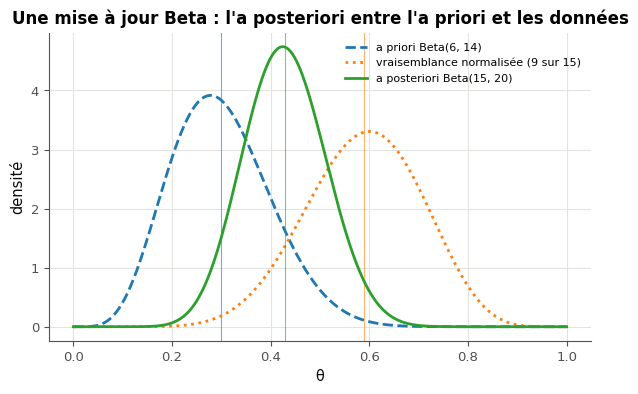

means: prior 0.3 · data 0.6 · posterior 0.42857142857142855


In [30]:
def draw_update(ax, a, b, k, n):
    """In ax: the prior Beta(a, b), the normalised likelihood of k successes in n trials, and the posterior, each
    with a label; then the legend and the name of the x axis."""
    theta = np.linspace(0, 1, 501)
    laws = [(stats.beta(a, b), f"a priori Beta({a}, {b})", "tab:blue", "--"),
            (stats.beta(k + 1, n - k + 1), f"vraisemblance normalisée ({k} sur {n})", "tab:orange", ":"),
            (stats.beta(a + k, b + n - k), f"a posteriori Beta({a + k}, {b + n - k})", "tab:green", "-")]
    for law, label, color, style in laws:
        ax.plot(theta, law.pdf(theta), style, color=color, linewidth=2, label=label)
        ax.axvline(law.mean(), color=color, linewidth=0.8, alpha=0.6)
    ax.set(xlabel="θ", ylabel="densité", title="Une mise à jour Beta : l'a posteriori entre l'a priori et les données")
    ax.legend(fontsize=8)


fig, ax = plt.subplots(figsize=(7, 4))
draw_update(ax, 6, 14, 9, 15)
plt.show()
print("means: prior", 6 / 20, "· data", 9 / 15, "· posterior", 15 / 35)

**Vérifications automatiques** (sur un autre exemple ; la figure elle-même se juge à l'œil).

In [31]:
with checked("M04.24 vérifications"):
    problems = []
    a_t, b_t, k_t, n_t = 3, 3, 2, 10                                       # another example
    expected = {"l'a priori": stats.beta(a_t, b_t), "la vraisemblance normalisée": stats.beta(k_t + 1, n_t - k_t + 1),
                "l'a posteriori": stats.beta(a_t + k_t, b_t + n_t - k_t)}
    fig, ax = plt.subplots(figsize=(6, 4))
    try:
        created = drawn(draw_update, ax, a_t, b_t, k_t, n_t)
    finally:
        plt.close(fig)                                                     # only the checks below are shown here
    if created:
        problems.append("draw_update ouvre sa propre figure : dessine dans l'axe reçu")
    else:
        curves = []
        for line in ax.get_lines():
            xs = np.asarray(line.get_xdata(), dtype=float)
            ys = np.asarray(line.get_ydata(), dtype=float)
            inside = (xs > 0.005) & (xs < 0.995)
            if inside.sum() >= 50:
                curves.append((line, xs[inside], ys[inside]))
        for name, law in expected.items():
            match = [line for line, xs, ys in curves if np.allclose(ys, law.pdf(xs), rtol=1e-6, atol=1e-6)]
            if not match:
                raw = [line for line, xs, ys in curves
                       if name == "la vraisemblance normalisée" and np.all(ys > 0)
                       and np.std(ys / (xs ** k_t * (1 - xs) ** (n_t - k_t))) < 1e-6 * np.mean(ys / (xs ** k_t * (1 - xs) ** (n_t - k_t)))]
                problems.append(f"{name} : la vraisemblance θ^k (1 − θ)^(n − k) doit être divisée par "
                                "B(k + 1, n − k + 1), pour avoir une aire de 1 comme les deux densités" if raw else
                                f"aucune courbe d'au moins 50 points sur ]0, 1[ n'est la densité de {name}"
                                + (" (a reçoit les succès, b les échecs)" if name == "l'a posteriori" else ""))
            else:
                if match[0].get_drawstyle() != "default" or match[0].get_linestyle() in ("None", "none", "", " "):
                    problems.append(f"{name} : trace une courbe continue (ax.plot), pas des points ni des marches")
                if not match[0].get_label() or match[0].get_label().startswith("_"):
                    problems.append(f"{name} : donne-lui un label, pour la légende")
        if ax.get_legend() is None:
            problems.append("il manque la légende (ax.legend())")
        if not ax.get_xlabel():
            problems.append("nomme l'axe des abscisses (θ)")
    if problems:
        print("❌ Ex M04.24 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex M04.24 : l'a priori, la vraisemblance normalisée et l'a posteriori sont justes, avec une légende.")

✅ Ex M04.24 : l'a priori, la vraisemblance normalisée et l'a posteriori sont justes, avec une légende.


💡 L'a posteriori $\mathrm{Beta}(15, 20)$ a sa moyenne $\frac{15}{35} \approx 0{,}43$ entre celle de l'a priori (0,3) et la fréquence observée (0,6), plus près de l'a priori : il vaut 20 observations, les données 15 (poids $\frac{15}{35}$ pour les données). L'a posteriori est aussi plus étroit que les deux autres courbes : il réunit les deux sources d'information. Avec 90 sur 150, les données pèseraient $\frac{150}{170}$ et l'a posteriori se collerait à la vraisemblance, autour de 0,56.

## Partie C · Erreurs classiques, calcul stable et défi

Fiche §1, §5 à §7. Quatre erreurs de mise à jour à trouver, une log-probabilité qui ne déborde jamais, puis l'avis d'un expert à traduire en loi Beta.

### Ex M04.25 — Chasse à l'erreur : évidence oubliée, mise à jour à l'envers, mode et moyenne 🐛 ★ ⏱️ 15 min
**Objectif :** repérer dans du code les erreurs classiques d'une mise à jour bayésienne, puis calculer les bonnes valeurs.  
**Prérequis :** fiche §1, §5 et §6 · **Parcours :** C

Un atelier contrôle les pièces d'un fournisseur.
- Sur le taux de défaut $\theta$ de ses pièces, l'atelier a l'a priori $\mathrm{Beta}(2, 18)$ ; sur 40 pièces contrôlées, 3 sont défectueuses (une pièce défectueuse est un « succès » pour $\theta$).
- Par ailleurs, un autre fournisseur est soit **fiable** (a priori 0,8 ; 5 % de pièces défectueuses), soit **douteux** (a priori 0,2 ; 20 % de pièces défectueuses). On tire une de ses pièces : elle est défectueuse.

Un analyste a écrit six lignes, chacune avec un commentaire qui dit ce qu'elle veut calculer. Quatre lignes sont fausses. **Sans exécuter de code**, trouve-les.

```python
b_A = 18 + 3                                   # (A) parameter b of the posterior of θ
p_B = 0.2 * 0.2                                # (B) P(douteux | défectueuse)
p_C = 0.8 * 0.05 + 0.2 * 0.2                   # (C) P(défectueuse), for the second supplier
mode_D = (2 + 3) / (2 + 18 + 40)               # (D) MAP of θ
mean_E = 5 / (5 + 55)                          # (E) posterior mean of θ
pred_F = 3 / 40                                # (F) P(the next piece is defective), for the first supplier
```

Questions :
- a) les lettres des lignes fausses, dans l'ordre alphabétique (un texte) ;
- b) pour chacune des six lignes, de (A) à (F), la bonne valeur de ce que dit son commentaire (une liste de 6 nombres, 3 décimales).

Dans ta copie : pour chaque ligne fausse, quelle confusion a été faite ? Laquelle des lignes justes aurait permis de corriger (B) ?

In [32]:
answer_M04_25a = "ABDF"
a_post, b_post = 2 + 3, 18 + 37                       # defective pieces go to a, good ones to b
evidence = 0.8 * 0.05 + 0.2 * 0.2                      # P(défectueuse): total probability
answer_M04_25b = [b_post,                              # (A)
                  0.2 * 0.2 / evidence,                # (B) divided by the evidence
                  evidence,                            # (C)
                  (a_post - 1) / (a_post + b_post - 2),  # (D) the mode
                  a_post / (a_post + b_post),          # (E) the mean
                  a_post / (a_post + b_post)]          # (F) the predictive is the posterior mean
print(answer_M04_25a, [round(v, 4) for v in answer_M04_25b])

ABDF [55, 0.5, 0.08, 0.069, 0.0833, 0.0833]


In [33]:
wbm.record("M04.25a", "ABDF",
           mistakes={"il manque une ligne fautive : vérifie, pour la mise à jour, quel paramètre reçoit les pièces défectueuses et lequel les bonnes": "BDF",
                     "il manque une ligne fautive : vérifie que chaque a posteriori est bien divisé par l'évidence": "ADF",
                     "il manque une ligne fautive : vérifie que chaque estimation utilise sa propre formule : le mode d'une loi Beta n'est pas sa moyenne": "ABF",
                     "il manque une ligne fautive : vérifie que chaque prédiction tient compte de l'a priori, et pas des seules données": "ABD",
                     "une ligne de trop : une des lignes que tu cites est correcte ; refais le calcul de chacune sur un petit exemple": {"ABCDF", "ABDEF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : vérifie, pour la mise à jour, quel paramètre reçoit les pièces défectueuses et lequel les bonnes": {"BCDF", "BDEF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : vérifie que chaque a posteriori est bien divisé par l'évidence": {"ACDF", "ADEF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : vérifie que chaque estimation utilise sa propre formule : le mode d'une loi Beta n'est pas sa moyenne": {"ABCF", "ABEF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : vérifie que chaque prédiction tient compte de l'a priori, et pas des seules données": {"ABCD", "ABDE"},
                     "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple": {"A", "B", "D", "F", "AB", "AD", "AF", "BD", "BF", "DF"},
                     "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple": {"C", "E", "AC", "AE", "BC", "BE", "CD", "CE", "CF", "DE", "EF", "ABC", "ABE", "ACD", "ACE", "ACF", "ADE", "AEF", "BCD", "BCE", "BCF", "BDE", "BEF", "CDE", "CDF", "CEF", "DEF", "ABCE", "ACDE", "ACEF", "BCDE", "BCEF", "CDEF", "ABCDE", "ABCEF", "ACDEF", "BCDEF"},
                     "plusieurs lignes que tu cites sont correctes : vérifie chacune avec un petit exemple": {"ABCDEF"}})
wbm.record("M04.25b", [55, 0.5, 0.08, 4 / 58, 5 / 60, 5 / 60], decimals=3,
           mistakes={"ce sont les valeurs des lignes ; donne les bonnes valeurs de ce que disent les commentaires":
                         [21, 0.04, 0.08, 5 / 60, 5 / 60, 3 / 40]})

WBM_ANSWER {"hash": "d098f1b52b7d9c133d7edfe026f97dacb1099c8de4501b267bede37e2df9a7cc", "id": "M04.25a", "kind": "str", "mistakes": {"0033e4f1bf8189fdf1836cf18be31469ef55a250ea414e14201d6219fb72d00a": "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple", "0127a62bd7b936dc3b9531d59875b16f5eb0d61c2961228b32456bf5942c0e00": "une des lignes que tu cites est correcte, et il manque une ligne fautive : vérifie que chaque a posteriori est bien divisé par l'évidence", "022adbf77cfef7fb78fe2b469aa283daad2edcc4f9953d95849d175597d00651": "il manque une ligne fautive : vérifie, pour la mise à jour, quel paramètre reçoit les pièces défectueuses et lequel les bonnes", "07939b576a46f1767870caee4aeb798c6024d6df6c017613190b687123ea3051": "une ligne de trop : une des lignes que tu cites est correcte ; refais le calcul de chacune sur un petit exemple", "0f5684ec650f540e9d2111cc43986fc775854f80fa14872dd15aa8bb60c624a7": "il manque des lignes fautives, et des lignes que tu cite

💡 (A) met à l'envers la mise à jour : les 3 pièces défectueuses vont à $a$, les 37 bonnes à $b$, donc $b = 18 + 37 = 55$. (B) oublie l'évidence : $\frac{0{,}2 \times 0{,}2}{0{,}08} = 0{,}5$ ; l'évidence est la ligne (C), juste. (D) calcule la moyenne $\frac{5}{60}$ au lieu du mode $\frac{5 - 1}{5 + 55 - 2} = \frac{4}{58} \approx 0{,}069$. (F) est le maximum de vraisemblance, sans l'a priori ; la probabilité que la pièce suivante soit défectueuse est la moyenne a posteriori $\frac{5}{60} \approx 0{,}083$, la ligne (E), juste.

### Ex M04.26 — Un calcul stable : comparer des vraisemblances en logarithmes (`math.lgamma`) 🛠️ ★ ⏱️ 15 min
**Objectif :** écrire une log-probabilité binomiale qui ne déborde jamais, cas limites compris, et s'en servir pour comparer des hypothèses sur de grands échantillons.  
**Prérequis :** fiche §7 ; R6 · **Parcours :** C

Avec 10 000 essais, la probabilité binomiale $\binom{n}{k}p^k(1 - p)^{n - k}$ ne se calcule pas directement : $p^k$ vaut 0 en `float64`, et $\binom{n}{k}$ est un entier de plus de 2 900 chiffres. La cellule fournie le montre. Les bibliothèques calculent donc son **logarithme** :

$$\ln P(K = k) = \ln\Gamma(n + 1) - \ln\Gamma(k + 1) - \ln\Gamma(n - k + 1) + k\ln p + (n - k)\ln(1 - p).$$

Écris `log_binom_pmf(k, n, p)`, qui renvoie ce logarithme en `float`, avec ces cas particuliers :
- $k < 0$ ou $k > n$ : la probabilité est nulle, renvoie `-math.inf` ;
- $p = 0$ ou $p = 1$ : `math.log(0)` lève une `ValueError`, mais $0 \times \ln 0$ vaut 0 par convention ; la probabilité vaut alors 1 ou 0 selon $k$ ;
- $p$ hors de $[0, 1]$, ou `nan` : une `ValueError` (teste `0 <= p <= 1` au début, ce qui refuse aussi `nan`).

La vérification compare ta fonction à `stats.binom.logpmf` sur neuf cas, puis une dernière cellule compare trois hypothèses sur $p$ pour 4 100 succès en 10 000 essais.

Dans ta copie : écris les trois log-vraisemblances, puis les a posteriori de la dernière cellule à la main, par log-sum-exp (fiche §7). Un écart $d$ entre deux log-vraisemblances fait un rapport $e^{d}$ entre leurs a posteriori (a priori égaux) : que donnent ici l'écart entre la première hypothèse et les deux autres, et l'écart entre les deux dernières ?

In [34]:
# The naive computation: 0.4 ** 4100 underflows to 0.0, then a huge integer times 0.0 overflows
try:
    naive_26 = math.comb(10_000, 4100) * 0.4 ** 4100 * 0.6 ** 5900
except OverflowError as exc:
    naive_26 = f"OverflowError: {exc}"
print("naive:", naive_26)

naive: OverflowError: int too large to convert to float


In [35]:
def log_binom_pmf(k, n, p):
    """The natural logarithm of the binomial probability P(K = k) for n trials of probability p; -math.inf when the
    probability is 0. ValueError if p is outside [0, 1]."""
    if not 0 <= p <= 1:
        raise ValueError(f"a probability is in [0, 1], got p = {p!r}")
    if k < 0 or k > n:
        return -math.inf
    log_coef = math.lgamma(n + 1) - math.lgamma(k + 1) - math.lgamma(n - k + 1)
    if p == 0:
        return 0.0 if k == 0 else -math.inf           # 0 × ln 0 = 0: only k = 0 is possible
    if p == 1:
        return 0.0 if k == n else -math.inf
    return float(log_coef + k * math.log(p) + (n - k) * math.log1p(-p))


print(log_binom_pmf(4100, 10_000, 0.4), "· scipy:", stats.binom.logpmf(4100, 10_000, 0.4))

-6.892232958563909 · scipy: -6.892232958542081


In [36]:
with checked("M04.26 vérifications"):
    problems = []
    cases = [(3, 10, 0.2), (0, 6, 0.0), (2, 6, 0.0), (7, 7, 1.0), (6, 7, 1.0), (4100, 10_000, 0.4),
             (12, 10, 0.3), (-1, 5, 0.5), (0, 0, 0.7)]
    for k, n, p in cases:
        expected = float(stats.binom.logpmf(k, n, p))
        try:
            got = log_binom_pmf(k, n, p)
        except NotImplementedError:
            raise
        except Exception as exc:  # noqa: BLE001
            problems.append(f"log_binom_pmf({k}, {n}, {p}) lève {type(exc).__name__} ({exc}) ; attendu {expected:.6g}"
                            + (" : 0 × ln 0 vaut 0 par convention, traite p = 0 et p = 1 à part" if p in (0.0, 1.0)
                               else ""))
            continue
        if not isinstance(got, float):
            problems.append(f"log_binom_pmf({k}, {n}, {p}) doit renvoyer un float de Python, pas {type(got).__name__}")
        elif math.isinf(expected):
            if got != -math.inf:
                problems.append(f"log_binom_pmf({k}, {n}, {p}) : attendu -math.inf (une probabilité nulle), "
                                f"obtenu {got!r}")
        elif not math.isclose(got, expected, rel_tol=1e-9, abs_tol=1e-9):
            problems.append(f"log_binom_pmf({k}, {n}, {p}) : attendu {expected:.10g}, obtenu {got!r}")
    for p in (1.2, -0.1, float("nan")):
        try:
            log_binom_pmf(2, 5, p)
        except ValueError:
            pass
        except NotImplementedError:
            raise
        except Exception as exc:  # noqa: BLE001
            problems.append(f"p = {p} : lève {type(exc).__name__} ; une probabilité hors de [0, 1] demande une ValueError")
        else:
            problems.append(f"p = {p} est accepté : une probabilité hors de [0, 1] demande une ValueError")
    if problems:
        print("❌ Ex M04.26 : à revoir : " + " ; ".join(problems[:5]) + ("…" if len(problems) > 5 else "."))
    else:
        print("✅ Ex M04.26 : des log-probabilités justes, cas limites compris, même pour n = 10 000.")

✅ Ex M04.26 : des log-probabilités justes, cas limites compris, même pour n = 10 000.


**Comparer trois hypothèses.** Cette cellule utilise ta fonction (elle affiche une erreur tant que `log_binom_pmf` n'est pas écrite).

In [37]:
# Three hypotheses on p, equal priors: the posteriors from the log-likelihoods, by log-sum-exp
P_26 = [0.38, 0.40, 0.42]
log_like_26 = np.array([log_binom_pmf(4100, 10_000, p) for p in P_26])
print("log-likelihoods:", log_like_26.round(3))
print("posteriors (equal priors):", np.exp(log_like_26 - special.logsumexp(log_like_26)).round(4))

log-likelihoods: [-23.735  -6.892  -6.872]
posteriors (equal priors): [0.     0.4949 0.5051]


💡 Les log-vraisemblances valent environ $-23{,}73$, $-6{,}89$ et $-6{,}87$ : 0,40 et 0,42 sont presque à égale distance de la fréquence 0,41, et 0,38 en est trois fois plus loin. Avec des a priori égaux, l'a posteriori de chaque hypothèse est $\frac{e^{\ell_j}}{\sum_i e^{\ell_i}}$ : environ 0,495 et 0,505 pour 0,40 et 0,42, et un écart de 16,8 entre log-vraisemblances fait un rapport $e^{16{,}8} \approx 2 \times 10^7$, d'où un a posteriori d'environ $2{,}4 \times 10^{-8}$ pour 0,38. Le cas $p = 0$ est le piège classique : `k * math.log(p)` lève une erreur même pour $k = 0$, alors que la probabilité de 0 succès vaut 1.

### Ex M04.27 — Défi : traduire l'avis d'un expert en une loi Beta (moyenne, écart-type, intervalle) 🏆 ★★★ ⏱️ 25 min
**Objectif :** construire un a priori Beta à partir d'une moyenne et d'un écart-type, puis à partir d'un intervalle, et mesurer ce qu'il pèse face aux données.  
**Prérequis :** fiche §4 à §6 ; M02a §6 (quantiles) · **Parcours :** C

Avant de lancer une nouvelle ligne de production, l'atelier interroge deux experts sur son taux de défaut $\theta$.
- Le premier dit : « environ 20 %, avec un écart-type de 5 points ».
- Le second dit : « j'ai 90 % de chances de ne pas me tromper en disant entre 10 % et 32 % », et l'on comprend que chaque queue laisse 5 %.

Traduis chaque avis en une loi Beta, puis calcule :
- a) les paramètres `[a, b]` de la loi Beta de moyenne 0,2 et d'écart-type 0,05 (1 décimale) ; pense à écrire la variance d'une loi Beta avec $m = \frac{a}{a + b}$ et $s = a + b$ : $\frac{m(1 - m)}{s + 1}$ ;
- b) les paramètres `[a, b]` de la loi Beta dont l'intervalle à 90 % à queues égales est $[0{,}10 ;\ 0{,}32]$ (1 décimale) ; aucune formule ne les donne : cherche-les par le calcul, par une recherche sur une grille ou avec `optimize.fsolve(f, x0)` (importé dans la cellule d'outils), qui part du point `x0` et cherche où la fonction `f`, qui renvoie une liste de deux nombres, vaut `[0, 0]` ;
- c) la probabilité $P(0{,}10 \le \theta \le 0{,}32)$ selon la loi de a) (4 décimales) ;
- d) la moyenne a posteriori après 7 pièces défectueuses sur 50, à partir de la loi de b), avec ses paramètres **non arrondis** (3 décimales) ;
- e) le nombre de pseudo-observations $a + b$ de la loi de b), avec ses paramètres non arrondis (1 décimale).

La vérification affiche l'intervalle et la moyenne de ta loi de b), puis vérifie tes réponses.

Dans ta copie : les deux experts sont-ils d'accord ? Lequel est le plus sûr de lui, et comment le lis-tu sur $a + b$ ? Après 50 pièces, que pèse chaque avis face aux données ?

In [38]:
# a) The method of moments: s = a + b solves m(1 − m)/(s + 1) = sd², then a = m s and b = (1 − m) s
m_27, sd_27 = 0.2, 0.05
s_27 = m_27 * (1 - m_27) / sd_27 ** 2 - 1
answer_M04_27a = [m_27 * s_27, (1 - m_27) * s_27]


# b) Two equations, two unknowns: the quantiles 0.05 and 0.95 must be 0.10 and 0.32. The unknowns are the logarithms
# of a and b, so that the solver never tries a negative parameter.
def gaps_27(log_parameters):
    a, b = np.exp(log_parameters)
    low, high = stats.beta(a, b).ppf([0.05, 0.95])
    return [low - 0.10, high - 0.32]


answer_M04_27b = list(np.exp(optimize.fsolve(gaps_27, np.log([5.0, 15.0]))))
a_b, b_b = answer_M04_27b
answer_M04_27c = stats.beta(*answer_M04_27a).cdf(0.32) - stats.beta(*answer_M04_27a).cdf(0.10)
answer_M04_27d = (a_b + 7) / (a_b + b_b + 50)
answer_M04_27e = a_b + b_b
print("a)", [round(v, 3) for v in answer_M04_27a], " b)", [round(float(v), 3) for v in answer_M04_27b],
      " c)", round(float(answer_M04_27c), 4), " d)", round(answer_M04_27d, 4), " e)", round(float(answer_M04_27e), 3))
print("check of b):", stats.beta(a_b, b_b).ppf([0.05, 0.95]), "· mean of b):", a_b / (a_b + b_b))

a) [12.6, 50.4]  b) [6.867, 27.477]  c) 0.9745  d) 0.1644  e) 34.345
check of b): [0.1  0.32] · mean of b): 0.19995547480138154


In [39]:
wbm.record("M04.27a", [12.6, 50.4], decimals=1,
           mistakes={"l'écart-type est 0,05 : la variance est son carré": [0.44, 1.76]})
wbm.record("M04.27b", [6.8673766, 27.4771525], decimals=1,
           mistakes={"un intervalle à 90 % à queues égales laisse 5 % de chaque côté : les quantiles 0,05 et 0,95":
                         [9.6399566, 38.9785348]})
wbm.record("M04.27c", 0.9744893644, decimals=4)
wbm.record("M04.27d", (6.8673766 + 7) / (34.3445291 + 50), decimals=3,
           mistakes={"la moyenne a posteriori part de la loi de b), pas de celle de a)": 19.6 / 113,
                     "garde les paramètres non arrondis de b) pour ce calcul": (6.9 + 7) / (34.4 + 50)})
wbm.record("M04.27e", 34.3445291, decimals=1,
           mistakes={"additionne les paramètres non arrondis de b), pas leurs arrondis": 34.4})

WBM_ANSWER {"decimals": 1, "element_hashes": ["99b3ffcb4338dc5920370b0a3c70a23ae70d29f254dafb3eee42141ea94f277d", "f328f46b7adb3c9a4f7ec8f1bd3ce014c440bc7bfe13793fdfd17f552752533b"], "hash": "7aef1b625076d45506459c5c6e494c994b4ce00a68bcc13ad071f55a881f1770", "id": "M04.27a", "kind": "array", "mistakes": {"2b7281079d89ca33e866192a20f78503d4e45ea1b46e4ba1050cba89032163ab": "l'écart-type est 0,05 : la variance est son carré"}, "shape": [2]}
📝 Ex M04.27a : réponse enregistrée (array, 1 décimale).
WBM_ANSWER {"decimals": 1, "element_hashes": ["6bba7598bd989edb4018986a613c18a68e033658b2d382363a7c312b5cf57f6c", "0e547f7008f699eb20bde22bb80144cdaaa4f8fb06eda1676c886ab8e8ecb572"], "hash": "3cbb06a2d8103c6b36f6dceb3034aab8553a2b07860da068cab88d7d3d53b355", "id": "M04.27b", "kind": "array", "mistakes": {"678ebf2be5fbad702de85e3404aa1b677c5d2875868dbf49d727068896cbd3e0": "un intervalle à 90 % à queues égales laisse 5 % de chaque côté : les quantiles 0,05 et 0,95"}, "shape": [2]}
📝 Ex M04.27b : rép

💡 a) $s + 1 = \frac{0{,}2 \times 0{,}8}{0{,}05^2} = 64$, donc $s = 63$, $a = 12{,}6$ et $b = 50{,}4$. b) $\mathrm{Beta}(6{,}9 ;\ 27{,}5)$ environ, de moyenne 0,20 elle aussi : les deux experts sont d'accord sur le centre. c) La loi du premier met 97 % de probabilité dans l'intervalle du second, contre 90 % pour la loi du second : le premier est plus sûr de lui, ce que dit aussi $a + b$ (63 contre 34). d) Avec 50 pièces, les données pèsent $\frac{50}{84{,}3} \approx 0{,}59$ face au second avis, et $\frac{50}{113} \approx 0{,}44$ face au premier : $\frac{6{,}87 + 7}{84{,}34} \approx 0{,}164$, contre $\frac{19{,}6}{113} \approx 0{,}173$.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu appliquer la formule de Bayes à plusieurs hypothèses, une fois ou en boucle, et calculer l'évidence ?
2. Sais-tu écrire une vraisemblance, trouver son maximum, et mettre à jour une loi Beta par conjugaison (moyenne, MAP, prédictive, intervalle) ?
3. Sais-tu calculer en logarithmes (log-sum-exp, `lgamma`, `betaln`) quand les probabilités deviennent minuscules ?

**La suite** : le chapitre 4 de workbookIA (la règle de Bayes, le posterior sur une grille, la loi Beta), puis M05a, les nombres en machine et l'encadrement.